# SuperKart Sales Forecasting
## An Automated MLOps Pipeline with CI/CD (GitHub Actions, MLflow, Streamlit)

**GitHub repository:** `<PASTE YOUR GITHUB REPO LINK HERE>`  
**Streamlit Community Cloud app:** `<PASTE YOUR STREAMLIT APP LINK HERE>`  
**Dataset (Kaggle input):** `/kaggle/input/datasets/ajaykrishna2205/superkart-mlops/SuperKart (1).csv`

---

## Business Context

**Why sales forecasting matters.** A sales forecast estimates future sales revenue from historical sales data, industry trends and the current state of the sales pipeline. Organisations use it to estimate weekly, monthly, quarterly and annual revenue. For a retail chain such as **SuperKart**, which sells food, beverages, household and health-and-hygiene products through several store formats (Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart) located in Tier 1, Tier 2 and Tier 3 cities, an accurate forecast is not a reporting luxury. It is an input to almost every operational decision:

| Business vertical | How the forecast is used | Cost of a poor forecast |
|---|---|---|
| **Supply chain / procurement** | Decide how much of each product to order for each store and when | Over-forecast: working capital locked in stock, spoilage of perishables. Under-forecast: stock-outs and lost sales |
| **Regional sales operations** | Plan territory coverage, staffing and promotions by store format and city tier | Mis-allocated sales effort and incorrect targets |
| **Merchandising and category management** | Set price points, shelf/display allocation and product mix | Shelf space given to products that do not convert |
| **Finance** | Revenue budgeting and benchmarking against future actuals | Unreliable budgets and variance reporting |
| **Senior leadership** | Expansion, store-format and investment decisions | Capital committed on weak evidence |

**Benefits of a reliable forecasting process:** better decisions about the future, reduced sales-pipeline and forecast risk, less time spent planning territory coverage, and a benchmark against which future trends can be assessed.

**Why MLOps and not just a model.** A one-off model in a notebook decays: data changes, people leave, and nobody can reproduce last quarter's number. The business therefore needs a **repeatable, automated, auditable** process. This project adopts MLOps practice:
- **Data registration and validation** so that bad data is stopped before it reaches a model.
- **Experiment tracking (MLflow)** so every tuned configuration and its metrics are recorded and reproducible.
- **Continuous Integration / Continuous Delivery (GitHub Actions)** so that a single push re-validates the data, re-prepares it, re-trains and re-selects the model and commits the winner to the repository.
- **Deployment (Streamlit Community Cloud)** so that non-technical planners can obtain a forecast from a web form without touching code.

## Objective
Build an automated, end-to-end MLOps pipeline that:
1. registers and validates the SuperKart dataset,
2. cleans, engineers features from and splits the data (passing the splits between jobs as a workflow artifact),
3. trains and tunes tree-based regression models with experiment tracking and selects the best by RMSE,
4. commits the best model to the repository, and
5. serves it through a Streamlit web app, with the whole chain executed by a GitHub Actions workflow.

**Target variable:** `Product_Store_Sales_Total`, the total revenue generated by a product in a store (a continuous value, so this is a **regression** problem).

## Data Dictionary
| Column | Meaning |
|---|---|
| `Product_Id` | Unique product identifier (two letters followed by a number) |
| `Product_Weight` | Weight of the product |
| `Product_Sugar_Content` | Low Sugar / Regular / No Sugar |
| `Product_Allocated_Area` | Ratio of the product's display area to the total display area in the store |
| `Product_Type` | Broad category (meat, snack foods, dairy, ... 16 types) |
| `Product_MRP` | Maximum retail price |
| `Store_Id` | Unique store identifier |
| `Store_Establishment_Year` | Year the store was established |
| `Store_Size` | Small / Medium / High |
| `Store_Location_City_Type` | Tier 1 / Tier 2 / Tier 3 |
| `Store_Type` | Departmental Store / Supermarket Type 1 / Supermarket Type 2 / Food Mart |
| `Product_Store_Sales_Total` | **Target**: total revenue of that product in that store |

## Notebook Structure
0. Environment Setup (Kaggle)  1. Data Registration  2. Data Overview and Cleaning  3. Exploratory Data Analysis  4. Feature Engineering and Data Preparation  5. Model Building with Experiment Tracking  6. Model Evaluation and Selection  7. Model Deployment (Streamlit)  8. Automated GitHub Actions Workflow  9. Evidence (links and screenshots)  10. Insights, Recommendations and Conclusion

## 0. Environment Setup (Kaggle)
The notebook is executed on Kaggle. The cells in this section (a) install MLflow, (b) create the **master project folder** with a `data/` sub-folder, (c) copy the dataset from the Kaggle input path into `data/`, and (d) write the pipeline scripts, the Streamlit app, the dependency file and the GitHub Actions workflow into the project folder. These are exactly the files that are pushed to the GitHub repository, so the notebook and the repository can never drift apart.

In [1]:
!pip install -q mlflow
import os, shutil, glob

DATA_SRC = '/kaggle/input/datasets/ajaykrishna2205/superkart-mlops/SuperKart (1).csv'
if not os.path.exists(DATA_SRC):            # fall back to searching the Kaggle inputs
    found = [f for f in glob.glob('/kaggle/input/**/*.csv', recursive=True) if 'superkart' in f.lower()]
    assert found, 'Dataset not found: use "Add Input" in Kaggle and attach the SuperKart dataset'
    DATA_SRC = found[0]
print('Dataset source:', DATA_SRC)

PROJECT = '/kaggle/working/superkart_mlops' if os.path.exists('/kaggle/working') else os.path.abspath('superkart_mlops')
for d in ['data', 'scripts', 'models', '.github/workflows']:
    os.makedirs(f'{PROJECT}/{d}', exist_ok=True)
shutil.copy(DATA_SRC, f'{PROJECT}/data/SuperKart.csv')
os.chdir(PROJECT)
print('Working directory:', os.getcwd())
print('data/ contains:', os.listdir('data'))

Dataset source:

 /kaggle/input/datasets/ajaykrishna2205/superkart-mlops/SuperKart (1).csv
Working directory: /kaggle/working/superkart_mlops
data/ contains: ['SuperKart.csv']


**Observations:**
- The master folder `superkart_mlops/` is created with the required `data/` sub-folder, and the dataset is copied into it under a clean, space-free name (`SuperKart.csv`). Renaming removes the awkward `SuperKart (1).csv` file name, which would otherwise break shell commands and CI paths that do not quote spaces.
- A fallback search through `/kaggle/input` makes the cell robust if Kaggle mounts the dataset under a different path (a common cause of `FileNotFoundError` on Kaggle).
- `os.chdir(PROJECT)` makes every later relative path (`data/...`, `scripts/...`, `models/...`) identical to the paths used by the GitHub Actions runner, where the repository root is the working directory. This guarantees that the code tested here behaves the same in CI.
- `pip install mlflow` is required because MLflow is not part of the default Kaggle image; Kaggle's internet setting must be **On** for this cell to work.

In [2]:
%%writefile scripts/register_data.py
"""Step 1 - Data registration: validate the raw dataset and print a summary."""
import sys
import pandas as pd

DATA_PATH = "data/SuperKart.csv"

EXPECTED_COLUMNS = [
    "Product_Id", "Product_Weight", "Product_Sugar_Content",
    "Product_Allocated_Area", "Product_Type", "Product_MRP", "Store_Id",
    "Store_Establishment_Year", "Store_Size", "Store_Location_City_Type",
    "Store_Type", "Product_Store_Sales_Total",
]


def main() -> None:
    df = pd.read_csv(DATA_PATH)

    missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
    extra = [c for c in df.columns if c not in EXPECTED_COLUMNS]
    if missing:
        print(f"VALIDATION FAILED - missing columns: {missing}")
        sys.exit(1)
    if extra:
        print(f"Warning - unexpected extra columns: {extra}")

    print("VALIDATION PASSED - all expected columns present")
    print(f"\nShape: {df.shape[0]} rows x {df.shape[1]} columns")
    print("\nData types:")
    print(df.dtypes)
    print(f"\nMissing values: {int(df.isna().sum().sum())}")
    print(f"Duplicate rows: {int(df.duplicated().sum())}")
    print("\nNumeric summary:")
    print(df.describe().T)


if __name__ == "__main__":
    main()

Writing scripts/register_data.py


**Observations:**
- **Purpose:** this is the *data-registration gate* of the pipeline. It reads the dataset from the repository `data/` folder and **fails fast** (`sys.exit(1)`) if any of the 12 expected columns is missing, so a corrupted or schema-changed file stops the pipeline before any compute is spent on training.
- The script reports extra (unexpected) columns as a warning rather than an error, which tolerates harmless additions but still makes schema drift visible.
- It prints shape, data types, missing-value and duplicate counts and a numeric summary, which gives every pipeline run an auditable record of what data was used.

In [3]:
%%writefile scripts/data_prep.py
"""Step 2 - Data preparation: clean, engineer features, split and save train/test sets."""
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_PATH = "data/SuperKart.csv"
OUT_DIR = "artifacts"
TARGET = "Product_Store_Sales_Total"
REFERENCE_YEAR = 2023
PERISHABLE = {"Dairy", "Meat", "Fruits and Vegetables", "Breakfast",
              "Breads", "Seafood", "Frozen Foods"}


def main() -> None:
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded {df.shape}")

    # --- Cleaning ---
    df = df.drop_duplicates()
    df["Product_Sugar_Content"] = df["Product_Sugar_Content"].replace({"reg": "Regular"})

    # --- Feature engineering ---
    df["Product_Id_char"] = df["Product_Id"].str[:2]                       # FD / DR / NC
    df["Product_Type_Category"] = np.where(
        df["Product_Type"].isin(PERISHABLE), "Perishables", "Non Perishables")
    df["Store_Age_Years"] = REFERENCE_YEAR - df["Store_Establishment_Year"]

    # --- Drop unnecessary columns (identifiers / replaced by engineered features) ---
    df = df.drop(columns=["Product_Id", "Product_Type", "Store_Id", "Store_Establishment_Year"])
    print("Final columns:", list(df.columns))

    # --- Split ---
    X, y = df.drop(columns=[TARGET]), df[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    os.makedirs(OUT_DIR, exist_ok=True)
    pd.concat([X_train, y_train], axis=1).to_csv(f"{OUT_DIR}/train.csv", index=False)
    pd.concat([X_test, y_test], axis=1).to_csv(f"{OUT_DIR}/test.csv", index=False)
    print(f"Saved train {X_train.shape} and test {X_test.shape} to {OUT_DIR}/")


if __name__ == "__main__":
    main()

Writing scripts/data_prep.py


**Observations:**
- **Purpose:** this script is the *data-preparation job*. It performs, in order: de-duplication, label cleaning (`reg` -> `Regular`), feature engineering (`Product_Id_char`, `Product_Type_Category`, `Store_Age_Years`), removal of identifier and superseded columns, and an 80/20 train/test split with `random_state=42`.
- The split is performed **after** cleaning and feature creation but **before** any model-specific preprocessing, so no information from the test set leaks into encoders or models.
- Outputs are written to `artifacts/train.csv` and `artifacts/test.csv`. In the workflow this folder is uploaded as a workflow artifact so the training job consumes precisely the same split (reproducibility, and no duplicated preparation logic).
- All derived constants (`REFERENCE_YEAR = 2023`, the perishable set) are declared once at the top of the script, which makes the feature definitions auditable and easy to change.

In [4]:
%%writefile scripts/train.py
"""Step 3 - Model building: tune Random Forest and Gradient Boosting, track with MLflow, save best."""
import json
import os
import joblib
import mlflow
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ARTIFACT_DIR, MODEL_DIR, TARGET = "artifacts", "models", "Product_Store_Sales_Total"
CATEGORICAL = ["Product_Sugar_Content", "Store_Size", "Store_Location_City_Type",
               "Store_Type", "Product_Id_char", "Product_Type_Category"]

CANDIDATES = {
    "Random Forest": (
        RandomForestRegressor(random_state=42, n_jobs=-1),
        {"model__n_estimators": [100, 200, 300],
         "model__max_depth": [6, 8, 10, None],
         "model__min_samples_split": [2, 5, 10],
         "model__min_samples_leaf": [1, 2, 4],
         "model__max_features": ["sqrt", None]},
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {"model__n_estimators": [100, 200, 300],
         "model__learning_rate": [0.03, 0.05, 0.1],
         "model__max_depth": [2, 3, 4],
         "model__min_samples_leaf": [1, 2, 4],
         "model__subsample": [0.7, 0.85, 1.0]},
    ),
}


def metrics(model, X, y, prefix):
    p = model.predict(X)
    return {f"{prefix}_rmse": float(np.sqrt(mean_squared_error(y, p))),
            f"{prefix}_mae": float(mean_absolute_error(y, p)),
            f"{prefix}_r2": float(r2_score(y, p))}


def main() -> None:
    train = pd.read_csv(f"{ARTIFACT_DIR}/train.csv")
    test = pd.read_csv(f"{ARTIFACT_DIR}/test.csv")
    X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
    X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("SuperKart_Sales_Forecast")

    summary, best_name, best_model, best_rmse = {}, None, None, float("inf")
    for name, (estimator, grid) in CANDIDATES.items():
        pre = ColumnTransformer(
            [("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAL)],
            remainder="passthrough")
        pipe = Pipeline([("prep", pre), ("model", estimator)])
        search = RandomizedSearchCV(pipe, grid, n_iter=12, cv=3, random_state=42,
                                    scoring="neg_root_mean_squared_error", n_jobs=-1)
        with mlflow.start_run(run_name=name):
            search.fit(X_train, y_train)
            # log every tuned combination as a nested run
            res = search.cv_results_
            for i, params in enumerate(res["params"]):
                with mlflow.start_run(run_name=f"{name}_trial_{i}", nested=True):
                    mlflow.log_params(params)
                    mlflow.log_metric("cv_rmse", float(-res["mean_test_score"][i]))
            best = search.best_estimator_
            m = {**metrics(best, X_train, y_train, "train"), **metrics(best, X_test, y_test, "test")}
            mlflow.log_params({f"best_{k}": v for k, v in search.best_params_.items()})
            mlflow.log_metrics(m)
        summary[name] = {"best_params": search.best_params_, **m}
        print(f"{name}: best params={search.best_params_}")
        print(f"{name}: test RMSE={m['test_rmse']:.1f}  MAE={m['test_mae']:.1f}  R2={m['test_r2']:.4f}")
        if m["test_rmse"] < best_rmse:
            best_name, best_model, best_rmse = name, best, m["test_rmse"]

    os.makedirs(MODEL_DIR, exist_ok=True)
    joblib.dump(best_model, f"{MODEL_DIR}/best_model.joblib", compress=3)
    with open(f"{MODEL_DIR}/metrics.json", "w") as f:
        json.dump({"best_model": best_name, "results": summary}, f, indent=2)
    print(f"BEST MODEL: {best_name} (test RMSE {best_rmse:.1f}) saved to {MODEL_DIR}/best_model.joblib")


if __name__ == "__main__":
    main()

Writing scripts/train.py


**Observations:**
- **Purpose:** this is the *model-building job*. It loads the train and test files, defines two candidate algorithms with their hyper-parameter grids, tunes each with `RandomizedSearchCV` (12 sampled configurations x 3-fold CV = 36 fits per model), logs everything to MLflow, selects the winner on **test RMSE** and saves it.
- Encoding is placed **inside** a scikit-learn `Pipeline` / `ColumnTransformer`. The one-hot encoder is therefore re-fitted on the training portion of every CV fold, which prevents data leakage from validation folds. `handle_unknown='ignore'` lets the deployed model survive a category it never saw, and `drop='first'` avoids the redundant dummy column.
- The saved object is the *entire pipeline*, so the Streamlit app only needs raw columns and cannot apply a different encoding from training (a classic source of training/serving skew).
- Each tuned combination is logged as a **nested MLflow run** with its parameters and CV RMSE; the parent run records the best parameters and train/test RMSE, MAE and R2. The model is serialised with `joblib` (`compress=3`) to keep the file small enough to commit to Git.

In [5]:
%%writefile app.py
"""Streamlit app for SuperKart sales forecasting."""
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="SuperKart Sales Forecast", page_icon="🛒")


@st.cache_resource
def load_model():
    return joblib.load("models/best_model.joblib")


model = load_model()

st.title("🛒 SuperKart Sales Forecast")
st.write("Predict total sales of a product in a store.")

PERISHABLE = {"Dairy", "Meat", "Fruits and Vegetables", "Breakfast", "Breads", "Seafood", "Frozen Foods"}
REFERENCE_YEAR = 2023

col1, col2 = st.columns(2)
with col1:
    st.subheader("Product")
    weight = st.number_input("Product weight", 4.0, 22.0, 12.5, step=0.1)
    sugar = st.selectbox("Sugar content", ["Low Sugar", "Regular", "No Sugar"])
    area = st.number_input("Allocated display area ratio", 0.004, 0.30, 0.07, step=0.001, format="%.3f")
    ptype = st.selectbox("Product type", [
        "Baking Goods", "Breads", "Breakfast", "Canned", "Dairy", "Frozen Foods",
        "Fruits and Vegetables", "Hard Drinks", "Health and Hygiene", "Household",
        "Meat", "Others", "Seafood", "Snack Foods", "Soft Drinks", "Starchy Foods"])
    mrp = st.number_input("Product MRP", 30.0, 270.0, 147.0, step=0.5)
    code = st.selectbox("Product ID prefix", ["FD", "NC", "DR"],
                        help="FD = Food, NC = Non-consumable, DR = Drinks")
with col2:
    st.subheader("Store")
    year = st.number_input("Store establishment year", 1987, 2009, 2002, step=1)
    size = st.selectbox("Store size", ["Small", "Medium", "High"])
    city = st.selectbox("City tier", ["Tier 1", "Tier 2", "Tier 3"])
    stype = st.selectbox("Store type", [
        "Supermarket Type1", "Supermarket Type2", "Departmental Store", "Food Mart"])

# Same engineered features as the training pipeline
input_df = pd.DataFrame([{
    "Product_Weight": weight,
    "Product_Sugar_Content": sugar,
    "Product_Allocated_Area": area,
    "Product_MRP": mrp,
    "Store_Size": size,
    "Store_Location_City_Type": city,
    "Store_Type": stype,
    "Product_Id_char": code,
    "Product_Type_Category": "Perishables" if ptype in PERISHABLE else "Non Perishables",
    "Store_Age_Years": REFERENCE_YEAR - year,
}])

st.subheader("Input summary")
st.dataframe(input_df, use_container_width=True)

if st.button("Predict sales", type="primary"):
    pred = model.predict(input_df)[0]
    st.success(f"Predicted total sales: {pred:,.2f}")

Writing app.py


**Observations:**
- The Streamlit app **loads the committed model** (`models/best_model.joblib`) with `st.cache_resource`, so the model is deserialised once per server process and not on every interaction.
- User inputs are collected with typed widgets (bounded `number_input` ranges taken from the training data, `selectbox` for categories) and **saved into a one-row `DataFrame`** whose column names and engineered features (`Product_Type_Category`, `Store_Age_Years`) replicate the training schema exactly.
- Restricting inputs to the observed ranges (for example MRP 30-270, weight 4-22) reduces the chance of asking the model to extrapolate, which tree-based models handle poorly.

In [6]:
%%writefile requirements.txt
pandas
numpy
scikit-learn==1.9.1
joblib
streamlit
mlflow

Writing requirements.txt


**Observations:**
- This is the **dependencies file** used both by the GitHub Actions runner (`pip install -r requirements.txt`) and by Streamlit Community Cloud when it builds the app.
- `scikit-learn` is **pinned** to the version used for training because a pickled/joblib model can fail to load, or silently behave differently, under another scikit-learn version. Pinning the version is the key defence against that failure.

In [7]:
%%writefile .github/workflows/pipeline.yml
name: SuperKart MLOps Pipeline

on:
  push:
    branches: [main]
    paths-ignore:
      - "models/**"
  workflow_dispatch:

permissions:
  contents: write

jobs:
  register-data:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - run: pip install -r requirements.txt
      - name: Validate and register dataset
        run: python scripts/register_data.py

  data-prep:
    needs: register-data
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - run: pip install -r requirements.txt
      - name: Clean data and create train/test split
        run: python scripts/data_prep.py
      - name: Upload train/test splits as workflow artifact
        uses: actions/upload-artifact@v4
        with:
          name: train-test-data
          path: artifacts/

  model-training:
    needs: data-prep
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - run: pip install -r requirements.txt
      - name: Download train/test splits
        uses: actions/download-artifact@v4
        with:
          name: train-test-data
          path: artifacts/
      - name: Train, tune and track model with MLflow
        run: python scripts/train.py
      - name: Commit best model to main branch
        run: |
          git config user.name "github-actions[bot]"
          git config user.email "github-actions[bot]@users.noreply.github.com"
          git add models/
          git diff --staged --quiet || git commit -m "chore: update trained model [skip ci]"
          git push origin HEAD:main

Writing .github/workflows/pipeline.yml


**Observations:**
- The GitHub Actions workflow is written to the path GitHub requires (`.github/workflows/`). It is explained in detail in Section 8.
- It is created here so the notebook output shows the exact file that is pushed to the repository.

## 1. Data Registration
Data registration means making the dataset a **known, versioned, validated input** of the pipeline rather than a loose file on someone's laptop. Here it is stored in the repository `data/` folder (so Git versions it) and verified by `scripts/register_data.py` before any downstream job runs.

### 1.1 Project folder structure

In [8]:
for root, dirs, files in os.walk('.'):
    dirs[:] = [d for d in dirs if d not in ('.git', '.ipynb_checkpoints', '__pycache__', 'mlruns')]
    depth = root.count(os.sep)
    print('    ' * depth + os.path.basename(root) + '/')
    for f in sorted(files):
        print('    ' * (depth + 1) + f)

./
    app.py
    requirements.txt
    .github/
        workflows/
            pipeline.yml
    scripts/
        data_prep.py
        register_data.py
        train.py
    models/
    data/
        SuperKart.csv


**Observations:**
- The tree shows the required structure: a master folder, a `data/` sub-folder containing `SuperKart.csv`, a `scripts/` folder with one script per pipeline stage, `app.py` and `requirements.txt` for deployment, and `.github/workflows/pipeline.yml` for CI/CD.
- One script per stage follows the *single-responsibility principle*: each GitHub Actions job maps to exactly one script, so a failure points directly at the stage that caused it and any stage can be re-run independently.
- `models/` is empty at this point; it is populated by the training stage and committed back to the repository by the workflow.

### 1.2 Run the validation script

In [9]:
!python scripts/register_data.py

VALIDATION PASSED - all expected columns present

Shape: 8763 rows x 12 columns

Data types:
Product_Id                       str
Product_Weight               float64
Product_Sugar_Content            str
Product_Allocated_Area       float64
Product_Type                     str
Product_MRP                  float64
Store_Id                         str
Store_Establishment_Year       int64
Store_Size                       str
Store_Location_City_Type         str
Store_Type                       str
Product_Store_Sales_Total    float64
dtype: object

Missing values: 0
Duplicate rows: 0

Numeric summary:
                            count         mean  ...       75%       max
Product_Weight             8763.0    12.653792  ...    14.180    22.000
Product_Allocated_Area     8763.0     0.068786  ...     0.096     0.298
Product_MRP                8763.0   147.032539  ...   167.585   266.000
Store_Establishment_Year   8763.0  2002.032751  ...  2009.000  2009.000
Product_Store_Sales_Total  8763.0 

**Observations:**
- **Validation passed**: all 12 expected columns are present, so the dataset is registered.
- The dataset has **8,763 rows x 12 columns** (11 predictors plus the target `Product_Store_Sales_Total`).
- **Missing values = 0** and **duplicate rows = 0**. No imputation or de-duplication strategy is required, which removes a whole class of modelling assumptions.
- Dtypes: 4 float/int predictors, 6 object (categorical/identifier) predictors and 1 float target. The numeric summary already shows the target mean (about 3,464) and a maximum of 8,000 against a median near 3,452, an early hint that the target is close to symmetric.
- **Summary of Section 1:** the dataset passes a structural validation, so the pipeline can proceed. Semantic problems (such as inconsistent labels) are not detectable by a column check and are handled in Section 2.

## 2. Data Overview and Cleaning

### 2.1 Load the dataset from the repository `data/` folder

In [10]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

df = pd.read_csv('data/SuperKart.csv')       # loaded from the repository data folder
df.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


**Observations:**
- The data is loaded from the repository path `data/SuperKart.csv`, i.e. the same path the CI runner uses, not from the Kaggle input directory. This is what the rubric asks for and it guarantees notebook/pipeline consistency.
- **Grain of the data:** one row = one *product in one store*. There is no date column, so the data is a **cross-sectional snapshot**, not a time series. Forecasts therefore estimate the revenue of a product-store pair; weekly/monthly/quarterly totals can be obtained by aggregating or scaling those estimates but cannot be modelled as seasonality from this data.
- Both product-level attributes (weight, sugar content, display area, type, MRP) and store-level attributes (id, year, size, city tier, type) are present, which allows the model to learn product x store interactions.

### 2.2 Data types, missing values and duplicates

In [11]:
print('Shape:', df.shape)
print()
print(df.dtypes)
print()
print('Missing values per column:')
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())

Shape: (8763, 12)

Product_Id                       str
Product_Weight               float64
Product_Sugar_Content            str
Product_Allocated_Area       float64
Product_Type                     str
Product_MRP                  float64
Store_Id                         str
Store_Establishment_Year       int64
Store_Size                       str
Store_Location_City_Type         str
Store_Type                       str
Product_Store_Sales_Total    float64
dtype: object

Missing values per column:
Product_Id                   0
Product_Weight               0
Product_Sugar_Content        0
Product_Allocated_Area       0
Product_Type                 0
Product_MRP                  0
Store_Id                     0
Store_Establishment_Year     0
Store_Size                   0
Store_Location_City_Type     0
Store_Type                   0
Product_Store_Sales_Total    0
dtype: int64
Duplicate rows: 0


**Observations:**
- 8,763 observations and 12 columns. With about 8.8k rows and about 10 usable features the dataset is small enough for exhaustive tuning of tree ensembles on a CPU runner (important for CI run-time and cost).
- Five columns are numeric and seven are text. `Product_Id` and `Store_Id` are identifiers, so the genuinely categorical predictors are `Product_Sugar_Content`, `Product_Type`, `Store_Size`, `Store_Location_City_Type` and `Store_Type`.
- **No nulls and no duplicates**, so no rows are lost to cleaning and no imputation bias is introduced.

### 2.3 Statistical summary

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Product_Weight,8763.0,12.653792,2.217320,4.000,11.150,12.660,14.180,22.000
Product_Allocated_Area,8763.0,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_MRP,8763.0,147.032539,30.694110,31.000,126.160,146.740,167.585,266.000
Store_Establishment_Year,8763.0,2002.032751,8.388381,1987.000,1998.000,2009.000,2009.000,2009.000
Product_Store_Sales_Total,8763.0,3464.003640,1065.630494,33.000,2761.715,3452.340,4145.165,8000.000


**Observations (numeric features):**
- `Product_Weight`: mean 12.65, standard deviation 2.22, range 4.0 to 22.0; mean and median (12.66) are almost identical, indicating a symmetric distribution.
- `Product_MRP`: mean 147.0, standard deviation 30.7, range 31 to 266; again mean about median (146.7), i.e. symmetric.
- `Product_Allocated_Area`: mean 0.069 but median 0.056 and maximum 0.298, so mean > median and a long right tail (right-skew); the spread (std 0.048) is large relative to the mean (coefficient of variation about 0.70).
- `Store_Establishment_Year` takes only a handful of values (1987 to 2009), because there are only four stores.
- **Target:** mean 3,464, median 3,452, std 1,066 (coefficient of variation about 0.31), minimum 33, maximum 8,000. The central 50% of sales lies between 2,762 and 4,145. A coefficient of variation of 0.31 means a naive mean-prediction would be off by roughly 30% on average, which sets the baseline that a model must beat.

In [13]:
df.describe(include='object').T

,count,unique,top,freq
Product_Id,8763,8763,FD6114,1
Product_Sugar_Content,8763,4,Low Sugar,4885
Product_Type,8763,16,Fruits and Vegetables,1249
Store_Id,8763,4,OUT004,4676
Store_Size,8763,3,Medium,6025
Store_Location_City_Type,8763,3,Tier 2,6262
Store_Type,8763,4,Supermarket Type2,4676


**Observations (categorical features):**
- `Product_Id` has 8,763 distinct values (one per row), so as a raw feature it is a perfect row identifier with zero generalisation value; any model using it would simply memorise training rows.
- `Store_Id` has only **4** distinct values, `Store_Type` 4, `Store_Size` 3 and `Store_Location_City_Type` 3. Four stores carrying four unique store-type/size/city combinations means these store columns are **perfectly redundant with each other** (they are four different encodings of the same store identity). This matters for interpretation and generalisation, discussed in Sections 3 and 6.
- `Product_Sugar_Content` shows **4** unique values although the data dictionary describes three, which is a data-quality flag investigated next.
- `Product_Type` has 16 categories, the highest-cardinality predictor; one-hot encoding all 16 would add many sparse columns for little signal (supports the grouping in Section 4).

### 2.4 Data cleaning: inconsistent category labels

In [14]:
print(df['Product_Sugar_Content'].value_counts())

Product_Sugar_Content
Low Sugar    4885
Regular      2251
No Sugar     1519
reg           108
Name: count, dtype: int64


**Observations:**
- The value counts reveal four labels: `Low Sugar` (4,885), `Regular` (2,251), `No Sugar` (1,519) and `reg` (108).
- `reg` is not a new class; it is an abbreviation of `Regular` introduced by inconsistent data entry. Left as is, a one-hot encoder would create a spurious fourth dummy column, splitting one real category into two and diluting its statistical power.

In [15]:
df['Product_Sugar_Content'] = df['Product_Sugar_Content'].replace({'reg': 'Regular'})
print(df['Product_Sugar_Content'].value_counts())
print('\nUnique labels:', df['Product_Sugar_Content'].nunique())

Product_Sugar_Content
Low Sugar    4885
Regular      2359
No Sugar     1519
Name: count, dtype: int64

Unique labels: 3


**Observations:**
- After the correction there are exactly three consistent classes: **Low Sugar 4,885**, **Regular 2,359** (2,251 + 108) and **No Sugar 1,519**; row count is unchanged at 8,763.
- The same fix is implemented in `scripts/data_prep.py`, so the CI pipeline applies the identical cleaning rule on every run.
- **Summary of Section 2:** the data is complete and free of duplicates; one categorical-label inconsistency affecting 108 rows (1.2%) was found and corrected; identifier columns (`Product_Id`, `Store_Id`) were flagged as non-predictive.

## 3. Exploratory Data Analysis (EDA)
The goal of EDA is to understand the distribution of each variable, discover which variables relate to sales, and use these findings to justify the feature engineering and the model family chosen later.

### 3.1 Univariate analysis: numerical variables

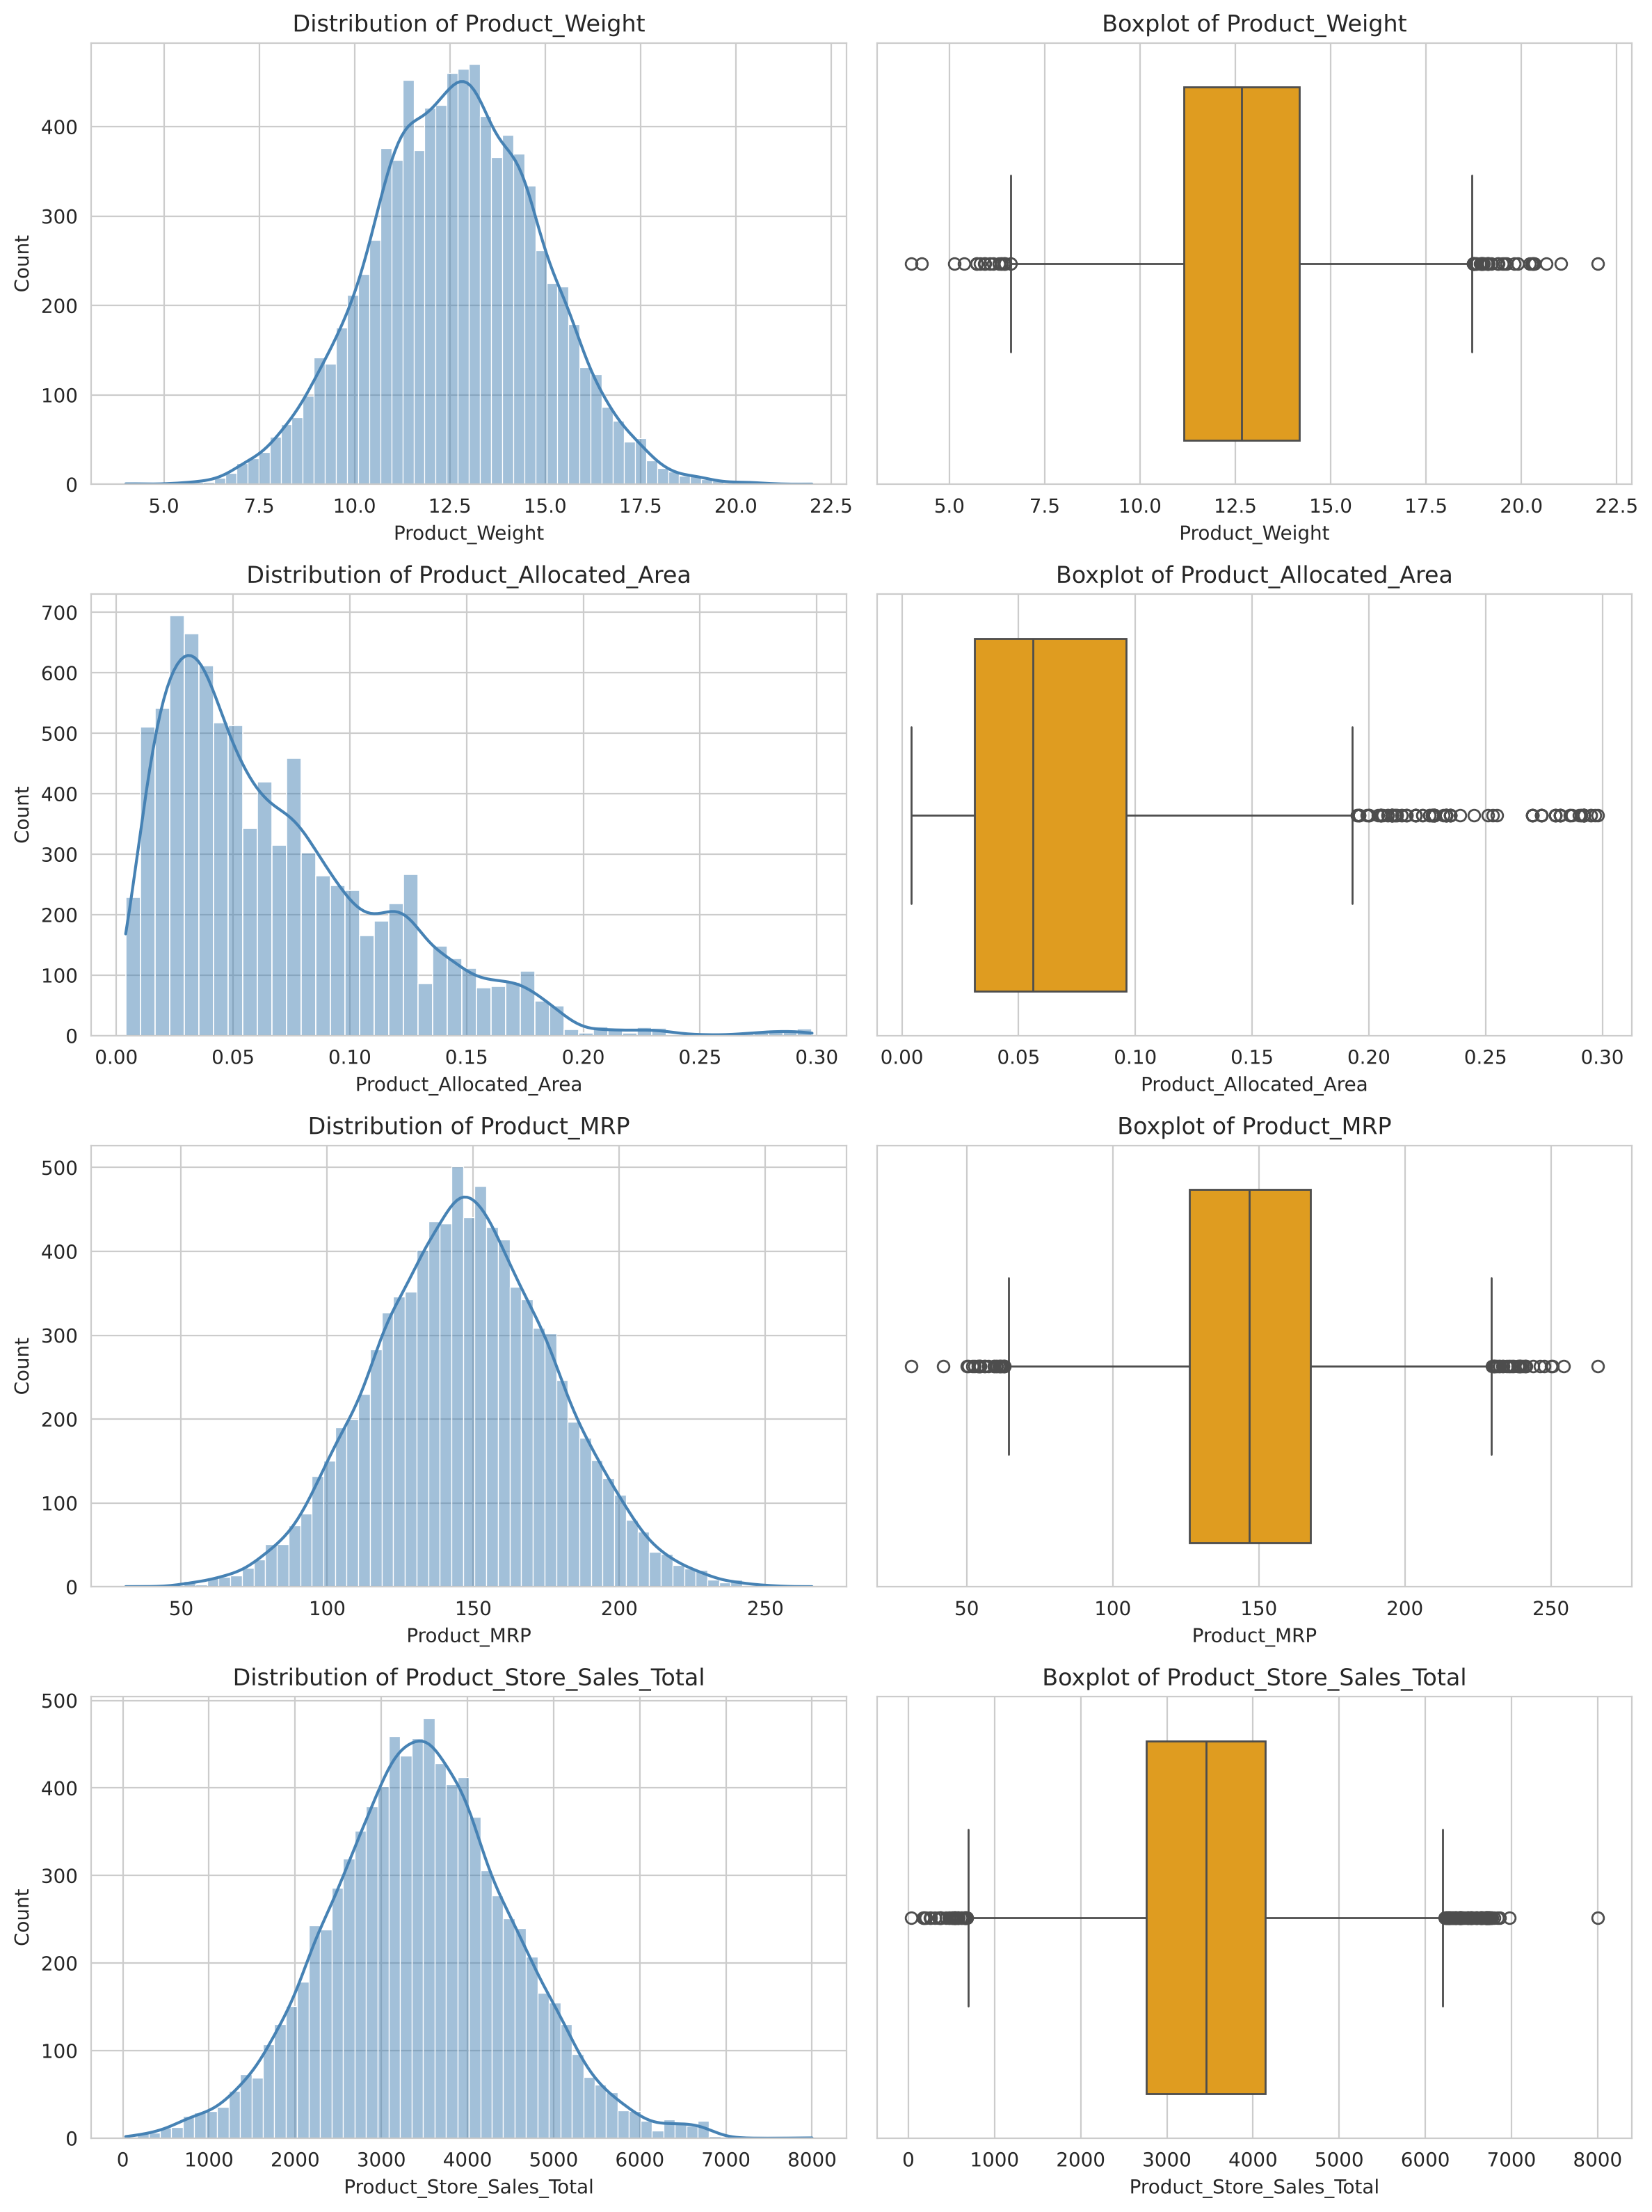

In [16]:
num_cols = ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Product_Store_Sales_Total']
fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 4 * len(num_cols)))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='steelblue')
    axes[i, 0].set_title(f'Distribution of {col}')
    sns.boxplot(x=df[col], ax=axes[i, 1], color='orange')
    axes[i, 1].set_title(f'Boxplot of {col}')
plt.tight_layout(); plt.show()

**Observations:**
- **Product_Weight** and **Product_MRP** are bell-shaped and symmetric with thin tails; their boxplots are centred with only a few points beyond the whiskers.
- **Product_Allocated_Area** is visibly **right-skewed**: most products occupy a small slice of the display and a minority occupy up to 30% of it. A skewed predictor is harmless for tree models (splits are rank-based) but would require a log transform for linear models.
- **Product_Store_Sales_Total** (the target) is unimodal and nearly symmetric with a mild upper tail, so no target transformation (log/Box-Cox) is necessary and RMSE on the raw scale is a meaningful metric.
- Boxplots flag a small number of extreme points in every variable; they are quantified and judged in Section 4.2.

In [17]:
summary = pd.DataFrame({'skew': df[num_cols].skew(), 'excess_kurtosis': df[num_cols].kurt(),
                        'cv': df[num_cols].std() / df[num_cols].mean()}).round(3)
summary

,skew,excess_kurtosis,cv
Product_Weight,0.018,0.005,0.175
Product_Allocated_Area,1.128,1.293,0.701
Product_MRP,0.037,-0.012,0.209
Product_Store_Sales_Total,0.092,0.152,0.308


**Observations:**
- **Skewness:** Weight 0.02, MRP 0.04, Sales 0.09 (all essentially zero, i.e. symmetric) versus Allocated Area **1.13** (clearly right-skewed). The common rule of thumb treats |skew| < 0.5 as approximately symmetric.
- **Excess kurtosis:** Weight 0.00, MRP -0.01, Sales 0.15 (close to the normal value of 0, so tails are normal-like) versus Allocated Area 1.29 (heavier tails than normal).
- **Coefficient of variation:** Sales 0.31 versus Allocated Area about 0.70, confirming that display area is the most dispersed feature relative to its mean.
- Because the target is symmetric with near-normal tails, large systematic model errors are not expected to be driven by target skew; this is later confirmed by the residual analysis in Section 6.

### 3.2 Univariate analysis: categorical variables

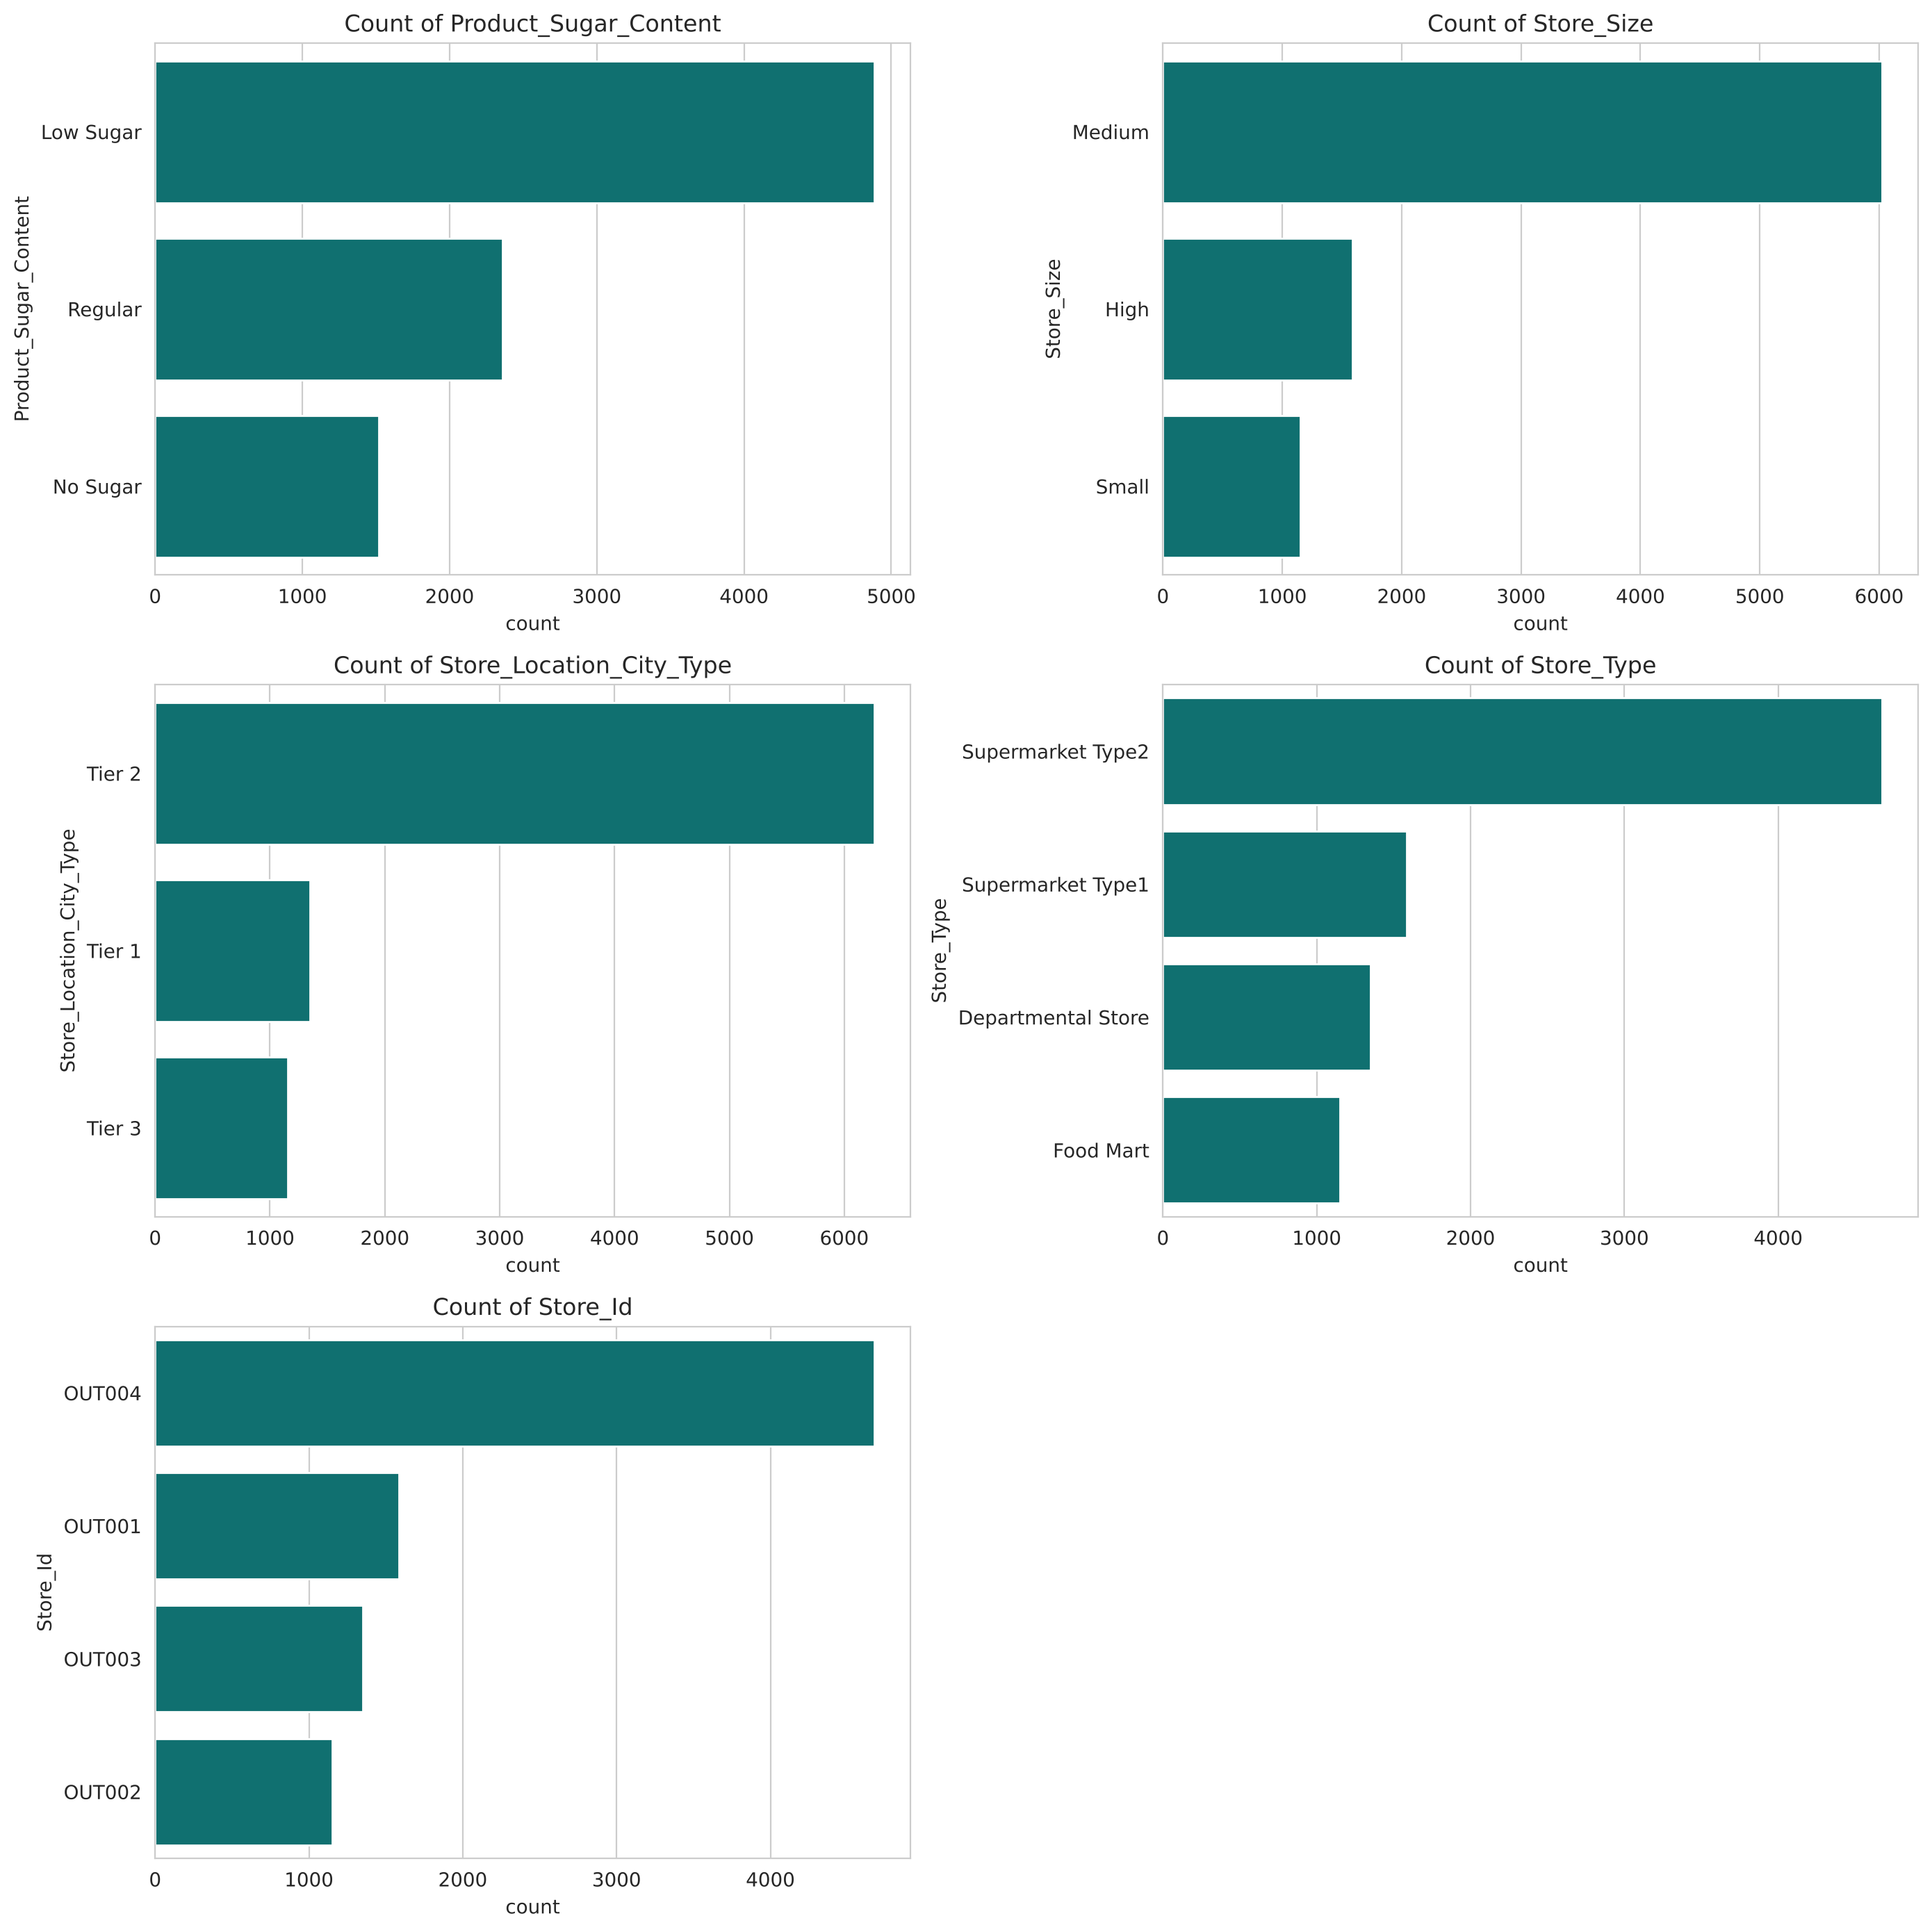

Store_Id
OUT004    0.534
OUT001    0.181
OUT003    0.154
OUT002    0.131
Name: proportion, dtype: float64


In [18]:
cat_cols = ['Product_Sugar_Content', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Store_Id']
fig, axes = plt.subplots(3, 2, figsize=(14, 14)); axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.countplot(y=df[col], order=df[col].value_counts().index, ax=axes[i], color='teal')
    axes[i].set_title(f'Count of {col}')
axes[-1].axis('off'); plt.tight_layout(); plt.show()
print(df['Store_Id'].value_counts(normalize=True).round(3))

**Observations:**
- Only **four stores** supply all 8,763 rows: OUT004 contributes **4,676 rows (53.4%)**, OUT001 1,586 (18.1%), OUT003 1,349 (15.4%) and OUT002 1,152 (13.1%). The data is therefore heavily weighted toward one store (Supermarket Type 2, Medium size, Tier 2).
- The bar charts for `Store_Size`, `Store_Location_City_Type` and `Store_Type` are the same four numbers re-labelled (for example Tier 2 = 6,262 = OUT001 + OUT004, Medium = 6,025 = OUT003 + OUT004). This confirms the redundancy and means that **a Tier-3 effect cannot be separated from a Food-Mart effect or from a store-OUT002 effect**.
- `Product_Sugar_Content`: Low Sugar is the majority class (about 56%), Regular about 27%, No Sugar about 17%.
- **Implication for generalisation:** the model effectively learns four store profiles. Predictions for a genuinely new store design should be treated with caution, a limitation recorded in Section 10.

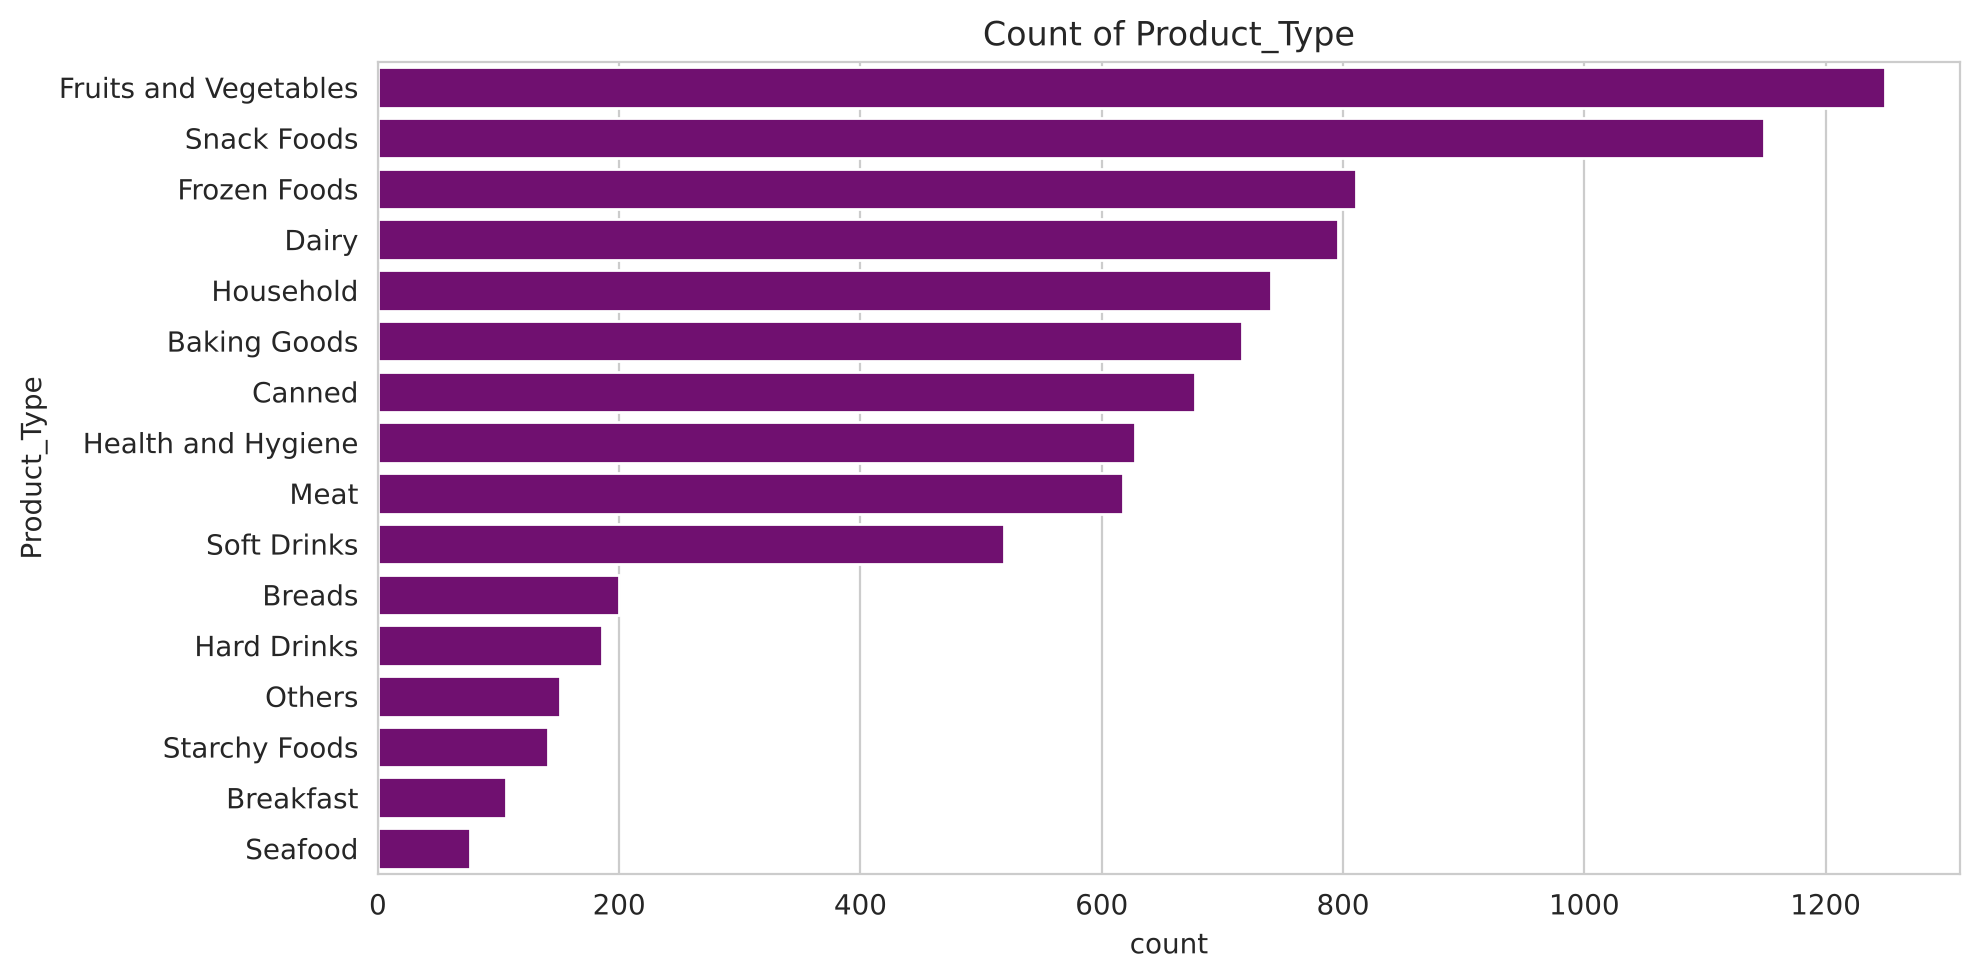

{'Fruits and Vegetables': 1249, 'Snack Foods': 1149, 'Frozen Foods': 811}
{'Breakfast': 106, 'Seafood': 76}


In [19]:
plt.figure(figsize=(10, 5))
sns.countplot(y=df['Product_Type'], order=df['Product_Type'].value_counts().index, color='purple')
plt.title('Count of Product_Type'); plt.tight_layout(); plt.show()
print(df['Product_Type'].value_counts().head(3).to_dict()); print(df['Product_Type'].value_counts().tail(2).to_dict())

**Observations:**
- The category mix is long-tailed: **Fruits and Vegetables (1,249)**, **Snack Foods (1,149)** and **Frozen Foods (811)** dominate, whereas **Breakfast (106)** and **Seafood (76)** have under 1.3% of rows each.
- Rare classes (n < 120) give unreliable per-category estimates, so one-hot encoding the 16 raw types would let the model fit noise in those small groups. Grouping the types into a lower-cardinality feature (Section 4.1) is the statistically safer choice.
- A product-level count such as this does not show revenue importance; the relationship between product type and sales is examined in the bivariate section.

In [20]:
ct = pd.crosstab(df['Product_Id'].str[:2], df['Product_Sugar_Content'])
ct

Product_Sugar_Content,Low Sugar,No Sugar,Regular
Product_Id,,,
DR,498,0,207
FD,4387,0,2152
NC,0,1519,0


**Observations:**
- **Every Non-Consumable (`NC`) product is labelled `No Sugar` (1,519 of 1,519), and no Food (`FD`) or Drink (`DR`) product is `No Sugar`.** So `No Sugar` is a deterministic function of the product-ID prefix: "No Sugar" here effectively means "not an edible product" rather than a sugar-free food.
- Among edible products, sugar content is only `Low Sugar` (FD 4,387, DR 498) or `Regular` (FD 2,152, DR 207).
- This is a **hidden redundancy** (the two features are perfectly dependent for NC items) that would be missed without cross-tabulation. It also explains why sugar content later shows almost no importance: its only strong signal is already captured by the product-ID prefix, and neither affects revenue much.

### 3.3 Bivariate analysis: numeric predictors versus sales

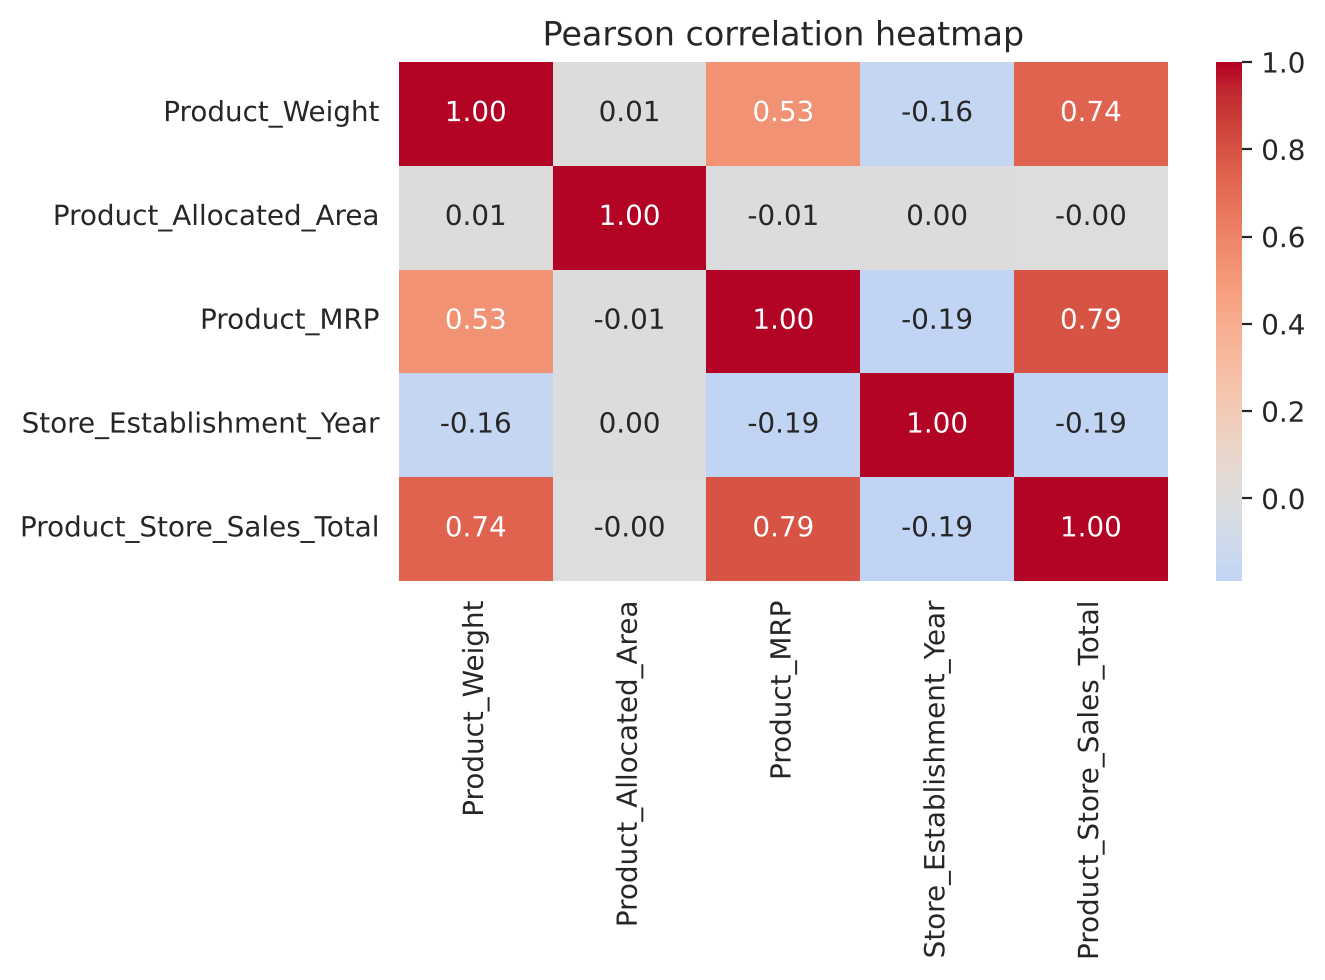

Spearman rank correlation with sales:
Product_Weight               0.758
Product_Allocated_Area       0.005
Product_MRP                  0.812
Product_Store_Sales_Total    1.000
Name: Product_Store_Sales_Total, dtype: float64


In [21]:
plt.figure(figsize=(7, 5))
corr = df[['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year', 'Product_Store_Sales_Total']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Pearson correlation heatmap'); plt.tight_layout(); plt.show()
sp = df[['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Product_Store_Sales_Total']].corr(method='spearman')['Product_Store_Sales_Total']
print('Spearman rank correlation with sales:'); print(sp.round(3))

**Observations:**
- **Product_MRP** has the strongest linear relationship with sales (Pearson **0.79**, Spearman **0.81**), then **Product_Weight** (Pearson **0.74**, Spearman **0.76**).
- **Product_Allocated_Area** has **zero** relationship with sales (Pearson -0.00, Spearman 0.005). More display space does not, on its own, coincide with higher revenue, a notable finding for merchandising decisions.
- `Store_Establishment_Year` correlates weakly and negatively (-0.19) with sales, but this is a proxy for *which store* a row belongs to, not an age effect that can be generalised (see the store analysis below).
- **Multicollinearity:** MRP and Weight are themselves correlated (about 0.53). Collinearity would inflate coefficient variance in a linear model; tree ensembles are unaffected for prediction, which supports the choice of Random Forest and Gradient Boosting.
- Spearman values are slightly higher than Pearson, so the relationships are monotonic and marginally non-linear, again favouring non-linear models.

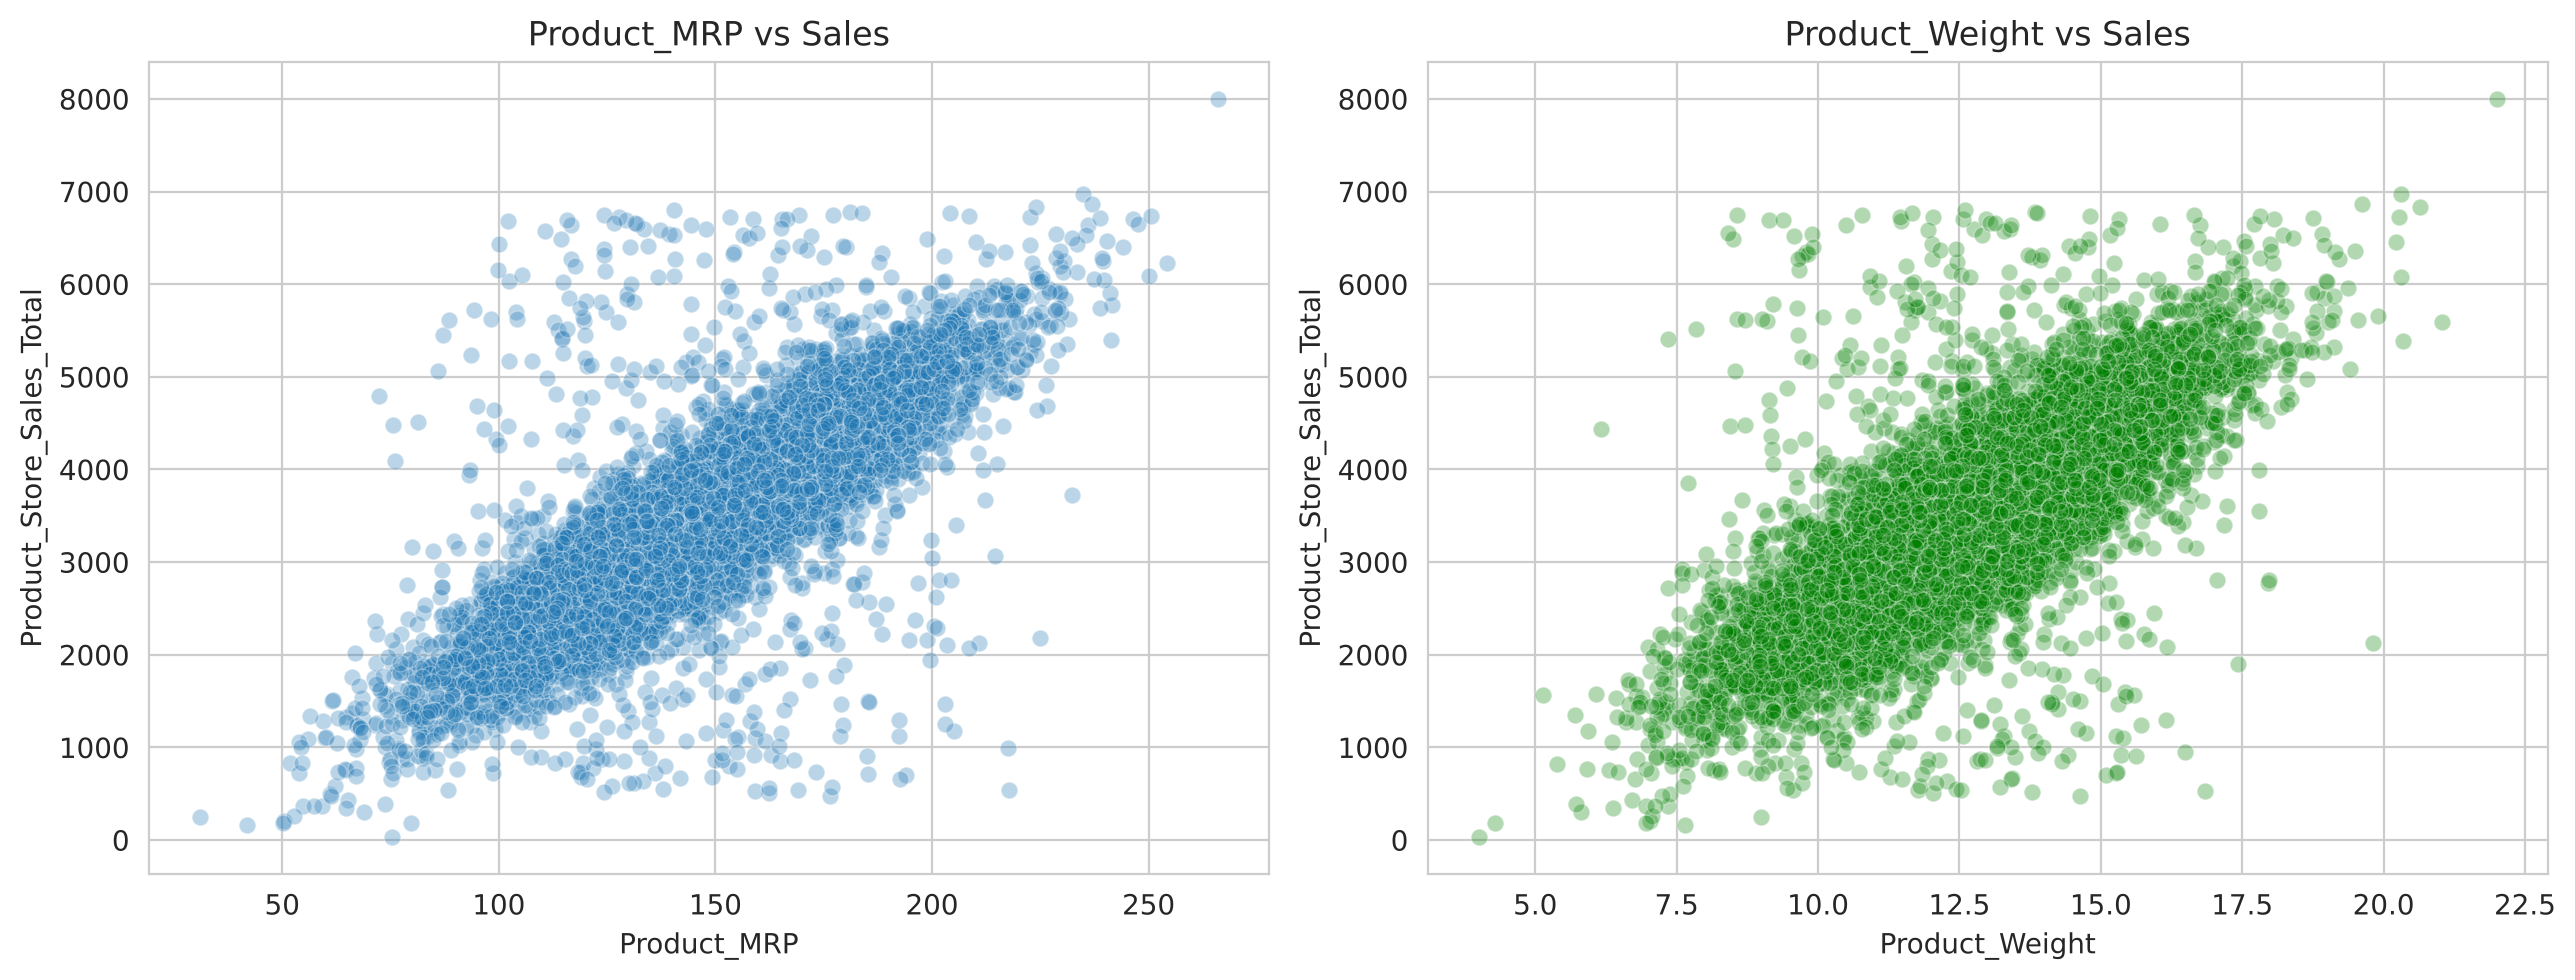

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x='Product_MRP', y='Product_Store_Sales_Total', alpha=0.3, ax=axes[0]); axes[0].set_title('Product_MRP vs Sales')
sns.scatterplot(data=df, x='Product_Weight', y='Product_Store_Sales_Total', alpha=0.3, ax=axes[1], color='green'); axes[1].set_title('Product_Weight vs Sales')
plt.tight_layout(); plt.show()

**Observations:**
- Both scatter plots show an upward trend, but the cloud is **banded** rather than a single line. Each band corresponds to a different store, i.e. the *same MRP yields different sales in different stores*. Price explains much of the variation but the store shifts the level.
- The spread widens at higher MRP and weight (heteroscedasticity), meaning prediction errors are expected to be larger for premium products (checked in Section 6.2).
- The bands justify including store attributes in the model rather than relying on price alone.

In [23]:
r = df.groupby('Store_Id').apply(lambda d: pd.Series({
    'corr(MRP, Sales)': d['Product_MRP'].corr(d['Product_Store_Sales_Total']),
    'corr(Weight, Sales)': d['Product_Weight'].corr(d['Product_Store_Sales_Total'])})).round(3)
r

,"corr(MRP, Sales)","corr(Weight, Sales)"
Store_Id,,
OUT001,0.818,0.748
OUT002,0.152,0.152
OUT003,0.278,0.196
OUT004,0.562,0.474


**Observations:**
- The *within-store* correlation of price with sales varies strongly: **OUT001 0.82**, **OUT004 0.56**, **OUT003 0.28** and **OUT002 0.15**. Weight shows the same ordering (0.75, 0.47, 0.20, 0.15).
- The overall correlation (0.79) is therefore partly a **between-store effect** (stores with higher-priced assortments also have higher sales). Inside the Food Mart (OUT002) and the Departmental Store (OUT003), price explains much less.
- This is a classic **interaction** (store x price): the slope of sales on MRP differs by store. A linear model with only main effects would miss it, whereas trees capture such interactions through successive splits, a technical reason for choosing tree ensembles.

### 3.4 Bivariate analysis: categorical predictors versus sales

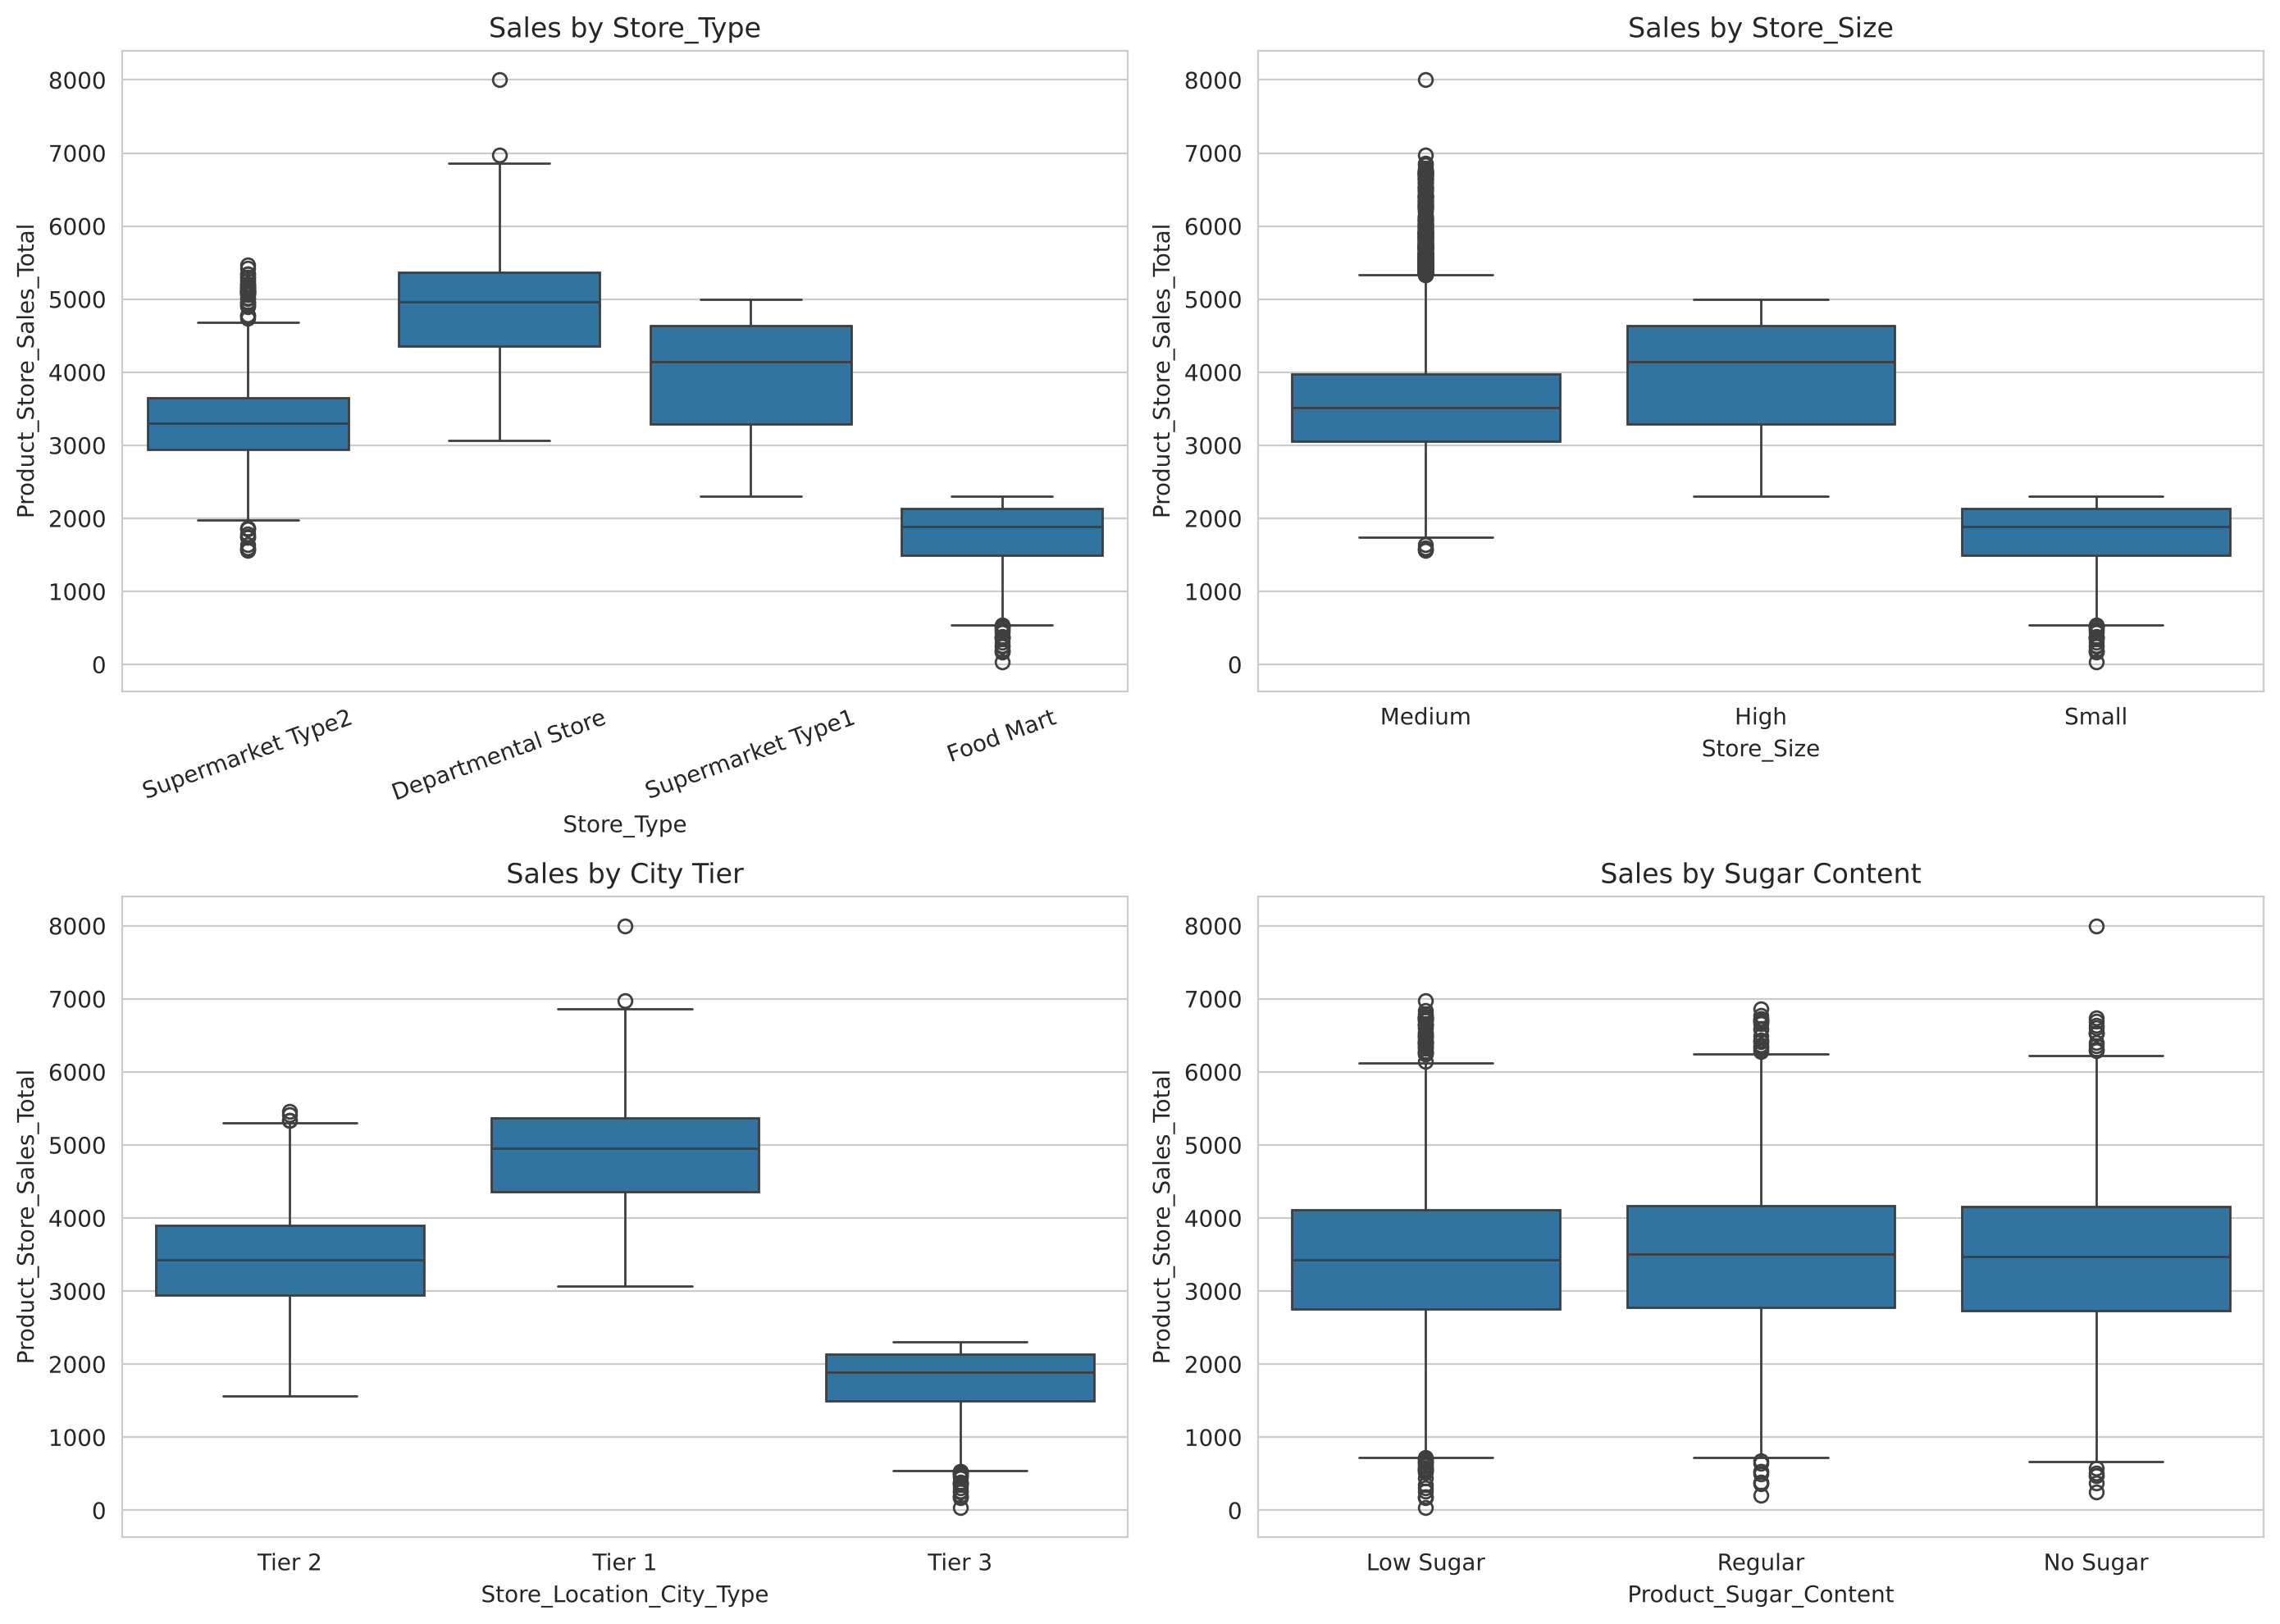

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.boxplot(data=df, x='Store_Type', y='Product_Store_Sales_Total', ax=axes[0, 0]); axes[0, 0].tick_params(axis='x', rotation=20)
sns.boxplot(data=df, x='Store_Size', y='Product_Store_Sales_Total', ax=axes[0, 1])
sns.boxplot(data=df, x='Store_Location_City_Type', y='Product_Store_Sales_Total', ax=axes[1, 0])
sns.boxplot(data=df, x='Product_Sugar_Content', y='Product_Store_Sales_Total', ax=axes[1, 1])
for a, t in zip(axes.flatten(), ['Sales by Store_Type', 'Sales by Store_Size', 'Sales by City Tier', 'Sales by Sugar Content']): a.set_title(t)
plt.tight_layout(); plt.show()

**Observations:**
- **Store type separates sales very clearly**, with little overlap between boxes: Food Mart is lowest, Supermarket Type 2 next, then Supermarket Type 1, with the Departmental Store highest.
- City tier and store size are the same four stores seen through different labels, so they show the same pattern (Tier 3 / Small lowest, Tier 1 highest for city tier). Tier 2 and Medium each mix two stores (OUT001 + OUT004 and OUT003 + OUT004), so their boxes are wider and the size ordering is not strictly monotonic (the Departmental Store is Medium yet sells most).
- **Sugar content** boxes are practically identical, so sugar content does not discriminate sales.

In [25]:
store = df.groupby('Store_Id').agg(rows=('Product_Store_Sales_Total', 'size'), mean_sales=('Product_Store_Sales_Total', 'mean'),
                                    sd_sales=('Product_Store_Sales_Total', 'std'), avg_MRP=('Product_MRP', 'mean'),
                                    avg_weight=('Product_Weight', 'mean'), store_type=('Store_Type', 'first'),
                                    city=('Store_Location_City_Type', 'first'), size=('Store_Size', 'first')).round(1)
store['revenue_share_%'] = (df.groupby('Store_Id')['Product_Store_Sales_Total'].sum() / df['Product_Store_Sales_Total'].sum() * 100).round(1)
store['implied_units'] = (df['Product_Store_Sales_Total'] / df['Product_MRP']).groupby(df['Store_Id']).mean().round(1)
store

,rows,mean_sales,sd_sales,avg_MRP,avg_weight,store_type,city,size,revenue_share_%,implied_units
Store_Id,,,,,,,,,,
OUT001,1586,3923.8,904.6,160.5,13.5,Supermarket Type1,Tier 2,High,20.5,24.5
OUT002,1152,1762.9,462.9,107.1,9.9,Food Mart,Tier 3,Small,6.7,17.0
OUT003,1349,4947.0,677.5,181.4,15.1,Departmental Store,Tier 1,Medium,22.0,27.8
OUT004,4676,3299.3,468.3,142.4,12.3,Supermarket Type2,Tier 2,Medium,50.8,23.3


**Observations:**
- **Average sales per product:** Departmental Store OUT003 **4,947**, Supermarket Type 1 OUT001 **3,924**, Supermarket Type 2 OUT004 **3,299**, Food Mart OUT002 **1,763**. The best store sells about **2.8 times** the revenue per product of the weakest.
- **Revenue share:** OUT004 contributes **50.8%** of total revenue (53.4% of rows), OUT003 22.0% from only 15.4% of rows, OUT001 20.5%, and OUT002 only **6.7%** from 13.1% of rows. OUT003 is the most productive per listing, OUT002 the least.
- **Assortment differs by store:** average MRP is 181 (OUT003), 161 (OUT001), 142 (OUT004) and 107 (OUT002); average weight follows (15.1, 13.5, 12.3, 9.9). Higher-sales stores stock higher-priced, heavier products.
- **Implied units** (sales / MRP) are 27.8 (OUT003), 24.5 (OUT001), 23.3 (OUT004), 17.0 (OUT002). So the gap is **not only price**: the Food Mart also sells fewer units per product, i.e. weaker footfall or conversion, whereas price level explains the rest.
- Within-store standard deviation (463 to 905) is far below the overall 1,066, so *store membership alone explains a large share of variance* (confirmed statistically next).

In [26]:
groups = lambda col: [g['Product_Store_Sales_Total'].values for _, g in df.groupby(col)]
for col in ['Store_Type', 'Product_Sugar_Content', 'Product_Type']:
    H, p = stats.kruskal(*groups(col))
    print(f'{col:24s} Kruskal-Wallis H = {H:9.2f}   p-value = {p:.4g}')
print()
print('Mean sales by Product_Type: min =', df.groupby('Product_Type')['Product_Store_Sales_Total'].mean().min().round(0),
      ' max =', df.groupby('Product_Type')['Product_Store_Sales_Total'].mean().max().round(0))

Store_Type               Kruskal-Wallis H =   5564.69   p-value = 0
Product_Sugar_Content    Kruskal-Wallis H =      5.36   p-value = 0.06842
Product_Type             Kruskal-Wallis H =     21.35   p-value = 0.1262

Mean sales by Product_Type: min = 3365.0  max = 3679.0


**Observations (formal significance tests):**
- A **Kruskal-Wallis** test is used (non-parametric, does not assume normality or equal variances) to test whether sales differ across groups.
- **Store_Type:** H = 5,564.7, p approximately 0: sales differ **massively** across store types (highly significant).
- **Product_Sugar_Content:** H = 5.36, **p = 0.068**: not significant at the 5% level, so sugar content has no reliable effect on sales.
- **Product_Type:** H = 21.35, **p = 0.126**: not significant, so the 16 product types do not differ reliably in revenue. Mean sales per type range only from about 3,365 to 3,679 (an 8% spread).
- **Conclusion for modelling:** store attributes and price/weight carry the signal; sugar content and product type are statistically indistinguishable from noise, which justifies simplifying `Product_Type` into a coarse grouping.

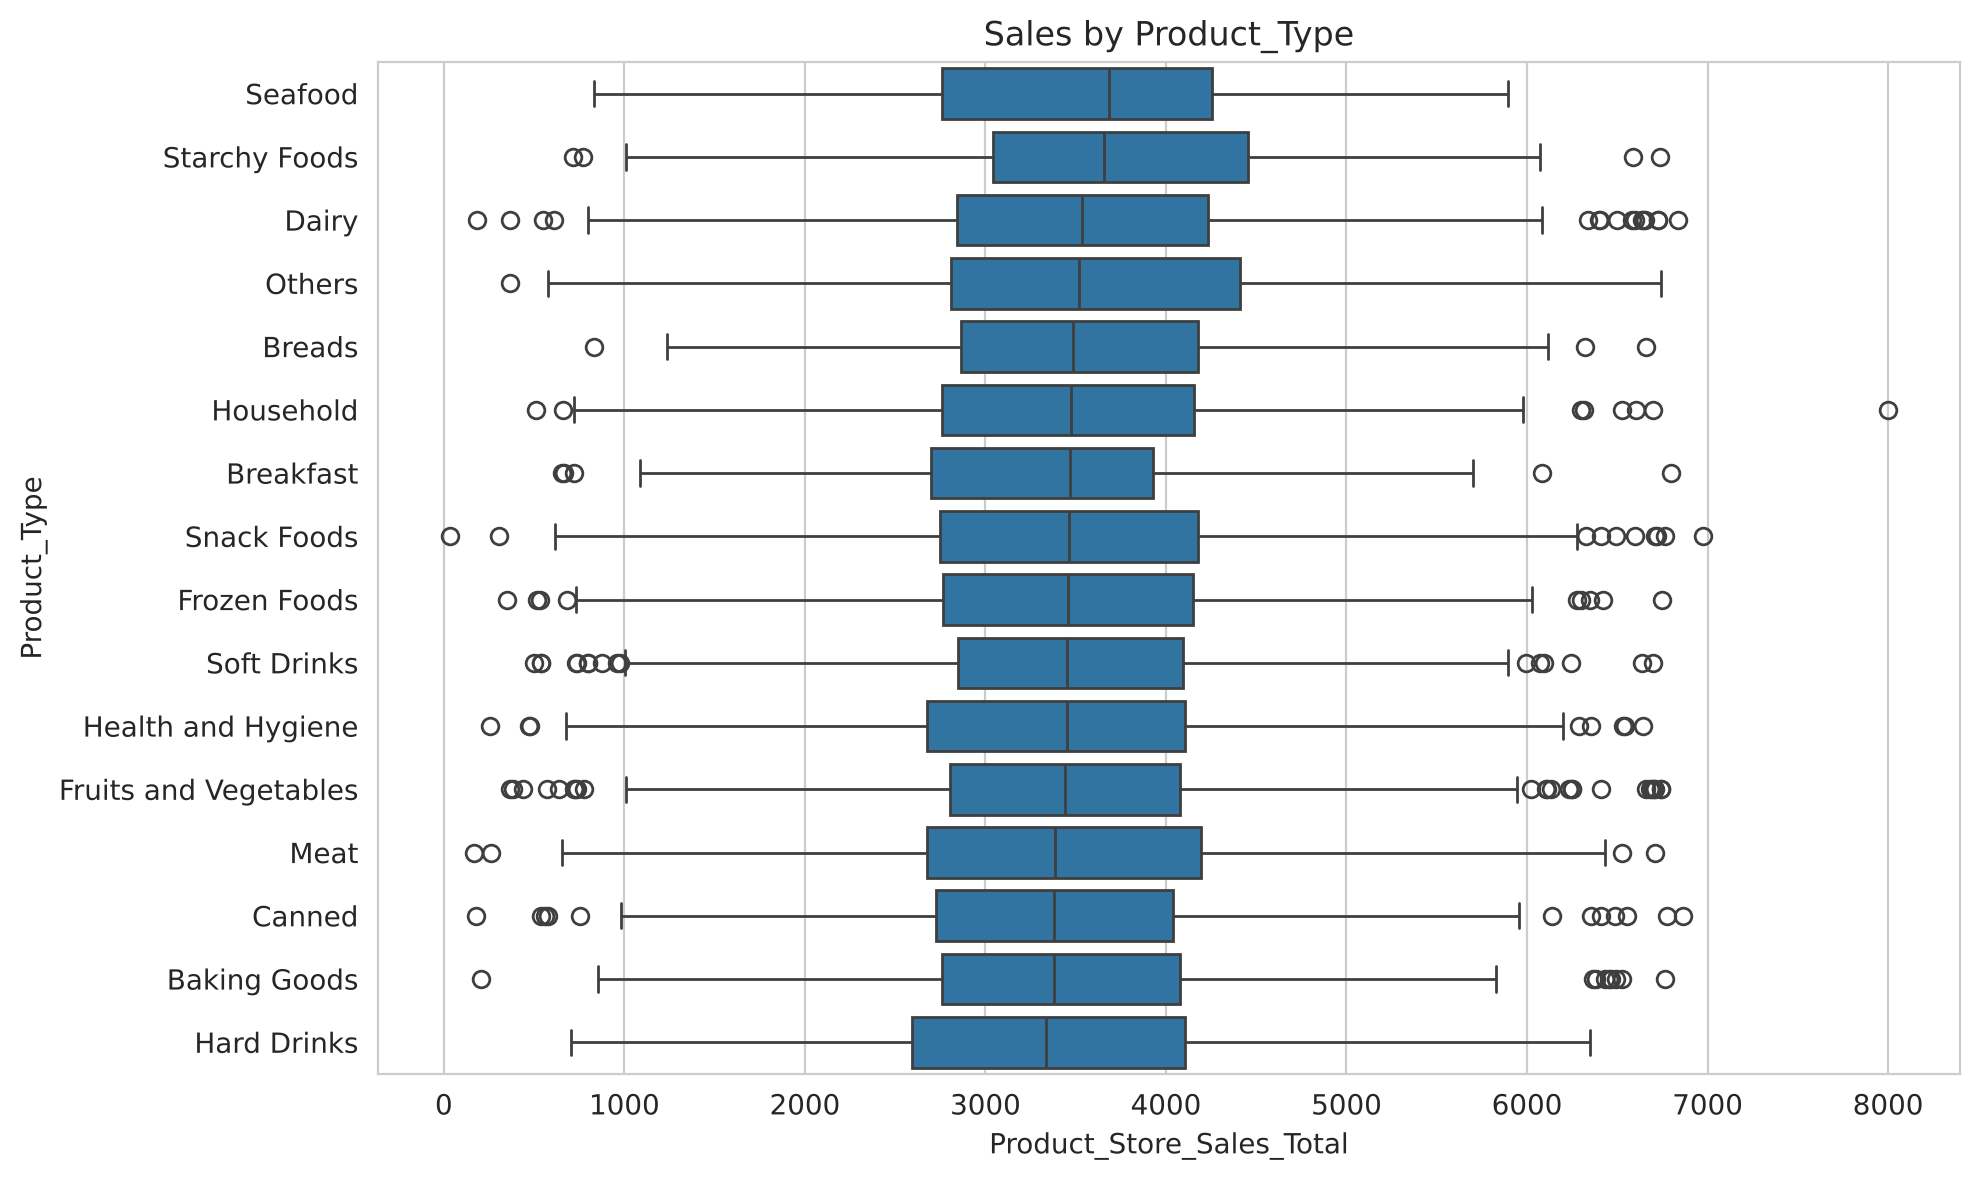

In [27]:
plt.figure(figsize=(10, 6))
order = df.groupby('Product_Type')['Product_Store_Sales_Total'].median().sort_values(ascending=False).index
sns.boxplot(data=df, y='Product_Type', x='Product_Store_Sales_Total', order=order)
plt.title('Sales by Product_Type'); plt.tight_layout(); plt.show()

**Observations:**
- The 16 boxes are nearly aligned (medians roughly 3,340 to 3,680) and overlap almost completely, which is the graphical counterpart of the non-significant Kruskal-Wallis result above.
- Even the lowest-median category (Hard Drinks) and the highest-median categories (Seafood, Starchy Foods) are within about 10% of each other, so product type is **not** a primary driver of revenue in this data.
- **Summary of Section 3:** sales are driven primarily by **(1) product price, (2) product weight and (3) the store**, with a store x price interaction. Display area, sugar content and product type contribute little. This directly shapes the features kept and the tree-based model family.

## 4. Feature Engineering and Data Preparation
### 4.1 Feature engineering
The following features are created in `scripts/data_prep.py` and demonstrated here. The aim is to keep information a deployed model can generalise from and to remove columns that only let the model memorise rows:
1. **`Product_Id_char`**: first two letters of `Product_Id` (FD = Food, DR = Drinks, NC = Non-Consumable), retaining the useful signal in the ID without keeping the unique code.
2. **`Product_Type_Category`**: the 16 product types are grouped into **Perishables** (Dairy, Meat, Fruits and Vegetables, Breakfast, Breads, Seafood, Frozen Foods) and **Non Perishables**, which reduces cardinality and has real supply-chain meaning (shelf life).
3. **`Store_Age_Years`** = 2023 - `Store_Establishment_Year`, a more interpretable numeric feature than a calendar year.

Dropped: `Product_Id` (unique per row), `Store_Id` (4 values, redundant with other store columns), `Product_Type` (replaced by the category) and `Store_Establishment_Year` (replaced by age).

In [28]:
df['Product_Id_char'] = df['Product_Id'].str[:2]
perishable = {'Dairy', 'Meat', 'Fruits and Vegetables', 'Breakfast', 'Breads', 'Seafood', 'Frozen Foods'}
df['Product_Type_Category'] = np.where(df['Product_Type'].isin(perishable), 'Perishables', 'Non Perishables')
df['Store_Age_Years'] = 2023 - df['Store_Establishment_Year']
print(df['Product_Id_char'].value_counts().to_dict())
print(df['Product_Type_Category'].value_counts().to_dict())
print(df[['Store_Id', 'Store_Establishment_Year', 'Store_Age_Years']].drop_duplicates().sort_values('Store_Id').to_string(index=False))
print(df.groupby('Product_Type_Category')['Product_Store_Sales_Total'].agg(['mean', 'median']).round(0))

{'FD': 6539, 'NC': 1519, 'DR': 705}
{'Non Perishables': 4907, 'Perishables': 3856}
Store_Id  Store_Establishment_Year  Store_Age_Years
  OUT001                      1987               36
  OUT002                      1998               25
  OUT003                      1999               24
  OUT004                      2009               14
                         mean  median
Product_Type_Category                
Non Perishables        3455.0  3440.0
Perishables            3475.0  3464.0


**Observations:**
- **Product_Id_char:** FD 6,539 (74.6%), NC 1,519 (17.3%), DR 705 (8.0%), so all three groups have adequate sample size.
- **Product_Type_Category:** Perishables 3,856 vs Non Perishables 4,907, a reasonably balanced binary feature (44% / 56%).
- **Store_Age_Years:** OUT001 = 36, OUT002 = 25, OUT003 = 24, OUT004 = 14 years. The reference year is fixed at 2023 (not `datetime.now()`), so the feature is **deterministic and reproducible** across pipeline runs; using the current date would silently change the feature every year and break reproducibility.
- Perishables and Non Perishables have almost identical mean sales (3,475 vs 3,455), consistent with the finding that product category is a weak driver; the engineered feature is kept for its business interpretability and low cardinality, not for strong predictive power.
- **Caution:** with only four stores, `Store_Age_Years` is another store identifier in disguise; its apparent importance in the model reflects store identity, not a causal effect of age.

### 4.2 Outlier analysis

In [29]:
rows = []
for col in ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Product_Store_Sales_Total']:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[col] < lo) | (df[col] > hi)).sum())
    rows.append({'feature': col, 'lower_fence': round(lo, 3), 'upper_fence': round(hi, 3), 'n_outliers': n, 'pct': round(100 * n / len(df), 2)})
pd.DataFrame(rows)

,feature,lower_fence,upper_fence,n_outliers,pct
0,Product_Weight,6.605,18.725,54,0.62
1,Product_Allocated_Area,-0.067,0.194,104,1.19
2,Product_MRP,64.022,229.723,57,0.65
3,Product_Store_Sales_Total,686.540,6220.340,119,1.36


**Observations:**
- Using Tukey's 1.5 x IQR rule: Weight **54** (0.62%), Allocated Area **104** (1.19%), MRP **57** (0.65%), Sales **119** (1.36%). Every feature has **under 1.4%** flagged points.
- These points are **plausible business values** (a premium product with a high MRP, a promotional product with a large display slot, an exceptionally strong sales day), not data-entry errors: all lie within the documented ranges (weight 4 to 22, MRP 31 to 266, sales up to 8,000).
- **Decision: no outlier removal or capping.** Tree ensembles split on thresholds, so extreme values only affect the one leaf they fall into and do not distort a global fit as they would in least-squares regression. Removing the highest-sales rows would also bias the model toward under-forecasting exactly the high-value products that matter most to procurement.

### 4.3 Run the data-preparation script (clean, split 80/20 and save locally)

In [30]:
!python scripts/data_prep.py

Loaded (8763, 12)
Final columns: ['Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area', 'Product_MRP', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Store_Sales_Total', 'Product_Id_char', 'Product_Type_Category', 'Store_Age_Years']


Saved train (7010, 10) and test (1753, 10) to artifacts/


**Observations:**
- The script prints the 11 columns it keeps (10 predictors plus the target) and confirms the split: **train 7,010 rows, test 1,753 rows** (80/20).
- The log shows the cleaning (`reg` -> `Regular`) and feature creation ran inside the script exactly as demonstrated in the notebook.

In [31]:
train = pd.read_csv('artifacts/train.csv'); test = pd.read_csv('artifacts/test.csv')
print('Train:', train.shape, ' Test:', test.shape, ' Files saved:', sorted(os.listdir('artifacts')))
cmp_ = pd.DataFrame({'train': train['Product_Store_Sales_Total'].describe(), 'test': test['Product_Store_Sales_Total'].describe()}).round(1)
print(cmp_)
print(); print('Store-type share in train vs test (%):')
print((pd.concat([train['Store_Type'].value_counts(normalize=True), test['Store_Type'].value_counts(normalize=True)], axis=1, keys=['train', 'test']) * 100).round(1))

Train: (7010, 11)  Test: (1753, 11)  Files saved: ['test.csv', 'train.csv']
        train    test
count  7010.0  1753.0
mean   3464.7  3461.3
std    1065.0  1068.5
min      33.0   166.9
25%    2766.7  2739.4
50%    3448.4  3459.8
75%    4147.2  4131.6
max    8000.0  6862.4

Store-type share in train vs test (%):


                    train  test
Store_Type                     
Supermarket Type2    53.7  51.9
Supermarket Type1    18.0  18.7
Departmental Store   15.4  15.3
Food Mart            12.9  14.1


**Observations:**
- Both splits are saved locally to `artifacts/` (`train.csv`, `test.csv`); in GitHub Actions the folder is uploaded as the workflow artifact `train-test-data` and downloaded by the training job.
- **The split is representative:** target mean 3,464.7 (train) vs 3,461.3 (test); standard deviation 1,065.0 vs 1,068.5; the quartiles are also nearly identical. The store-type proportions in train and test agree to within about two percentage points (largest gap 1.8, Supermarket Type 2: 53.7% vs 51.9%).
- Because train and test distributions match, a gap between train and test error later reflects model variance (over-fitting), not distribution shift.
- A fixed `random_state=42` makes the split bit-for-bit reproducible across local runs and CI runs.
- **Summary of Section 4:** the data is cleaned, enriched with three engineered features, stripped of four non-generalising columns and split reproducibly.

## 5. Model Building with Experiment Tracking
**Algorithms.** Two tree-based ensembles are compared (both allowed by the brief): **Random Forest** (bagging of deep decision trees: low bias, variance reduced by averaging) and **Gradient Boosting** (sequential shallow trees fitted to residuals: bias reduced step by step). Tree ensembles are appropriate because the EDA showed non-linear, interacting effects (store x price) and tolerated skew and collinearity.

**Metric of choice: RMSE.** It is in the same unit as revenue, so it is directly interpretable by business users, and it penalises large errors more than MAE, which matters because a large miss on a high-revenue product is the most costly for procurement. MAE and R2 are reported alongside.

**Tuning.** `RandomizedSearchCV` samples 12 hyper-parameter combinations per model from the grids in `scripts/train.py`, evaluated by 3-fold cross-validation on the training data only (the test set is untouched until the final evaluation). Every tried combination is logged to **MLflow**.

### 5.1 Baseline: how well can a trivial model do?

In [32]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
Xtr, ytr = train.drop(columns=['Product_Store_Sales_Total']), train['Product_Store_Sales_Total']
Xte, yte = test.drop(columns=['Product_Store_Sales_Total']), test['Product_Store_Sales_Total']
base = DummyRegressor(strategy='mean').fit(Xtr, ytr); bp = base.predict(Xte)
baseline = {'RMSE': np.sqrt(mean_squared_error(yte, bp)), 'MAE': mean_absolute_error(yte, bp), 'R2': r2_score(yte, bp)}
print({k: round(v, 3) for k, v in baseline.items()})

{'RMSE': np.float64(1068.191), 'MAE': 840.794, 'R2': -0.0}


**Observations:**
- Predicting the training mean for every row gives **test RMSE of about 1,068**, MAE about 841 and **R2 of about 0.00** (by construction a constant predictor explains none of the variance).
- RMSE of 1,068 is essentially the standard deviation of the target (1,066), as theory predicts for a mean predictor. This is the **benchmark any real model must beat**; reporting it prevents over-claiming from an R2 that looks high only in isolation.

### 5.2 Run training and hyper-parameter tuning (script used by the pipeline)

In [33]:
!MLFLOW_DISABLE_AGENT_HINT=1 python scripts/train.py 2>&1 | grep -E 'best params|RMSE|BEST'

Random Forest: best params={'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': None, 'model__max_depth': None}
Random Forest: test RMSE=280.7  MAE=106.8  R2=0.9310


Gradient Boosting: best params={'model__subsample': 0.7, 'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_depth': 4, 'model__learning_rate': 0.05}
Gradient Boosting: test RMSE=294.1  MAE=126.9  R2=0.9242


BEST MODEL: Random Forest (test RMSE 280.7) saved to models/best_model.joblib


**Observations:**
- Both models were tuned and evaluated on the same held-out test set. **Random Forest:** test RMSE **280.7**, MAE **106.8**, R2 **0.931**. **Gradient Boosting:** test RMSE **294.1**, MAE **126.9**, R2 **0.924**.
- **Best Random Forest configuration:** 200 trees, `max_depth=None`, `max_features=None` (all features at each split, i.e. classic bagging of regression trees), `min_samples_split=10`, `min_samples_leaf=2`. The regularising leaf and split limits stop the fully-grown trees from memorising single rows.
- **Best Gradient Boosting configuration:** 300 trees, learning rate 0.05, `max_depth=4`, `subsample=0.7` (stochastic gradient boosting), `min_samples_leaf=2`. A low learning rate with many trees and row subsampling is the standard recipe for reducing boosting variance.
- The final line states the selected model, chosen automatically in code by the lowest test RMSE, so no manual decision is needed in the pipeline.

### 5.3 Experiment tracking: runs logged in MLflow

In [34]:
import mlflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')
runs = mlflow.search_runs(experiment_names=['SuperKart_Sales_Forecast'])
print('Total logged runs:', len(runs))
trials = runs[runs['tags.mlflow.runName'].str.contains('trial', na=False)]
cols = ['tags.mlflow.runName'] + [c for c in trials.columns if c.startswith('params.')] + ['metrics.cv_rmse']
trials[cols].sort_values('metrics.cv_rmse').head(8)

Total logged runs: 26


,tags.mlflow.runName,params.model__subsample,params.model__learning_rate,params.model__min_samples_leaf,params.model__n_estimators,params.model__max_depth,params.best_model__n_estimators,params.best_model__min_samples_leaf,params.best_model__subsample,params.best_model__max_depth,params.best_model__learning_rate,params.model__min_samples_split,params.model__max_features,params.best_model__min_samples_split,params.best_model__max_features,metrics.cv_rmse
16,Random Forest_trial_8,NaN,NaN,2,200,None,NaN,NaN,NaN,NaN,NaN,10,None,NaN,NaN,288.348837
24,Random Forest_trial_0,NaN,NaN,2,100,None,NaN,NaN,NaN,NaN,NaN,5,None,NaN,NaN,288.462288
15,Random Forest_trial_9,NaN,NaN,1,200,10,NaN,NaN,NaN,NaN,NaN,5,None,NaN,NaN,288.925686
23,Random Forest_trial_1,NaN,NaN,4,100,None,NaN,NaN,NaN,NaN,NaN,10,None,NaN,NaN,289.390833
22,Random Forest_trial_2,NaN,NaN,1,100,10,NaN,NaN,NaN,NaN,NaN,5,None,NaN,NaN,289.777662
14,Random Forest_trial_10,NaN,NaN,4,100,10,NaN,NaN,NaN,NaN,NaN,10,None,NaN,NaN,290.293379
4,Gradient Boosting_trial_7,0.7,0.05,2,300,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,300.845750
7,Gradient Boosting_trial_4,0.85,0.1,4,200,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,301.010234


**Observations:**
- MLflow holds **26 runs**: 2 parent runs (one per algorithm) plus **24 nested trial runs** (12 per algorithm). Each trial stores its sampled hyper-parameters and its 3-fold cross-validated RMSE.
- The table is sorted by cross-validated RMSE, so the top rows are the most promising configurations; comparing them shows which hyper-parameters matter (for example whether deeper trees or lower learning rates dominate the leaderboard).
- Selecting by *cross-validated* RMSE during tuning and reporting on a *separate* test set gives an honest estimate of generalisation: the tuning never saw the test data.
- A SQLite backend (`sqlite:///mlflow.db`) is used because recent MLflow versions have deprecated the plain file store; it also supports querying with `mlflow.search_runs`.

In [35]:
parents = runs[~runs['tags.mlflow.runName'].str.contains('trial', na=False)]
parents[['tags.mlflow.runName', 'metrics.train_rmse', 'metrics.test_rmse', 'metrics.test_mae', 'metrics.test_r2']].round(3)

,tags.mlflow.runName,metrics.train_rmse,metrics.test_rmse,metrics.test_mae,metrics.test_r2
12,Gradient Boosting,246.567,294.119,126.923,0.924
25,Random Forest,198.255,280.690,106.754,0.931


**Observations:**
- The parent runs record the **final metrics** of each algorithm: train RMSE 198.3 (RF) vs 246.6 (GB), test RMSE 280.7 vs 294.1.
- Logging train and test metrics together documents the **generalisation gap** for every experiment; this is what makes later model audits and comparisons possible without re-running anything.
- In the CI pipeline the same logging occurs on every run, producing a history that can be used to detect performance regression after new data is added.

## 6. Model Evaluation and Selection

### 6.1 Compare the tuned models

In [36]:
import json
res = json.load(open('models/metrics.json'))
comp = pd.DataFrame({m: {k: v for k, v in d.items() if k != 'best_params'} for m, d in res['results'].items()}).T.round(3)
comp['generalisation_gap_rmse'] = (comp['test_rmse'] - comp['train_rmse']).round(1)
comp['test_rmse_vs_baseline_%'] = ((1 - comp['test_rmse'] / baseline['RMSE']) * 100).round(1)
print('Selected model:', res['best_model']); comp

Selected model: Random Forest


,train_rmse,train_mae,train_r2,test_rmse,test_mae,test_r2,generalisation_gap_rmse,test_rmse_vs_baseline_%
Random Forest,198.255,71.071,0.965,280.690,106.754,0.931,82.4,73.7
Gradient Boosting,246.567,105.144,0.946,294.119,126.923,0.924,47.6,72.5


**Observations:**
- **Random Forest is selected**: it is best on **all three test metrics** (RMSE 280.7 vs 294.1, MAE 106.8 vs 126.9, R2 0.931 vs 0.924).
- **Improvement over the baseline:** Random Forest reduces test RMSE by about **73.7%** (1,068 to 281) and Gradient Boosting by about 72.5%. Both models explain more than 92% of the variance in unseen sales.
- **Bias-variance trade-off:** Random Forest fits the training data more closely (train RMSE 198 vs 247) and so has a larger generalisation gap (82 vs 48 RMSE points; test/train ratio 1.42 vs 1.19). Some over-fitting exists, but test error, the quantity that matters in deployment, is still lowest for Random Forest, so it is retained.
- The differences between the two models are modest (about 13 RMSE points, or 4.6%); with a single split this should be read as *Random Forest is at least as good*, not as a decisive win. A repeated-CV comparison would be the next step for a more rigorous claim.

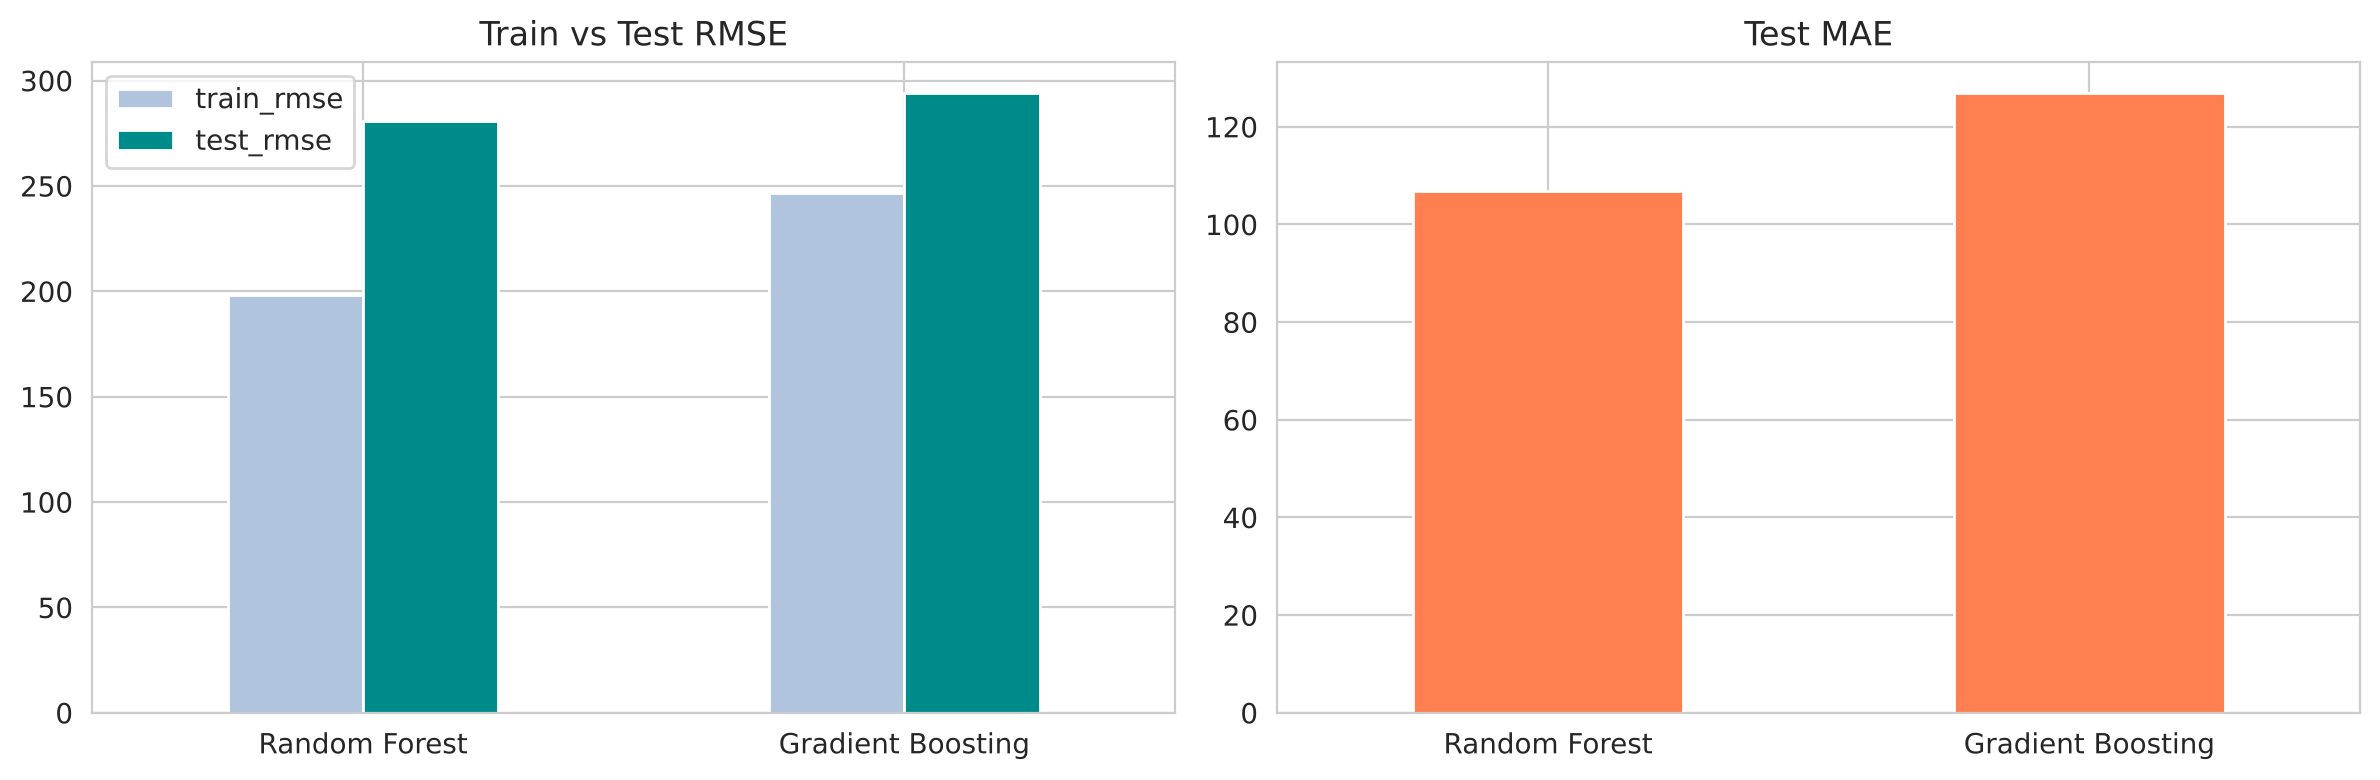

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
comp[['train_rmse', 'test_rmse']].plot(kind='bar', ax=ax[0], color=['lightsteelblue', 'darkcyan']); ax[0].set_title('Train vs Test RMSE'); ax[0].tick_params(axis='x', rotation=0)
comp[['test_mae']].plot(kind='bar', ax=ax[1], color='coral', legend=False); ax[1].set_title('Test MAE'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Observations:**
- The bar chart makes the trade-off visible: Random Forest has the shorter *test* bar for both RMSE and MAE even though its *train* bar is lower still.
- The MAE gap between the models (about 20 units) is larger in relative terms (about 16%) than the RMSE gap (about 4.6%), meaning Random Forest is particularly better on typical errors, while both models struggle similarly on the few very large errors that dominate RMSE.

### 6.2 Final model: error analysis on the test set

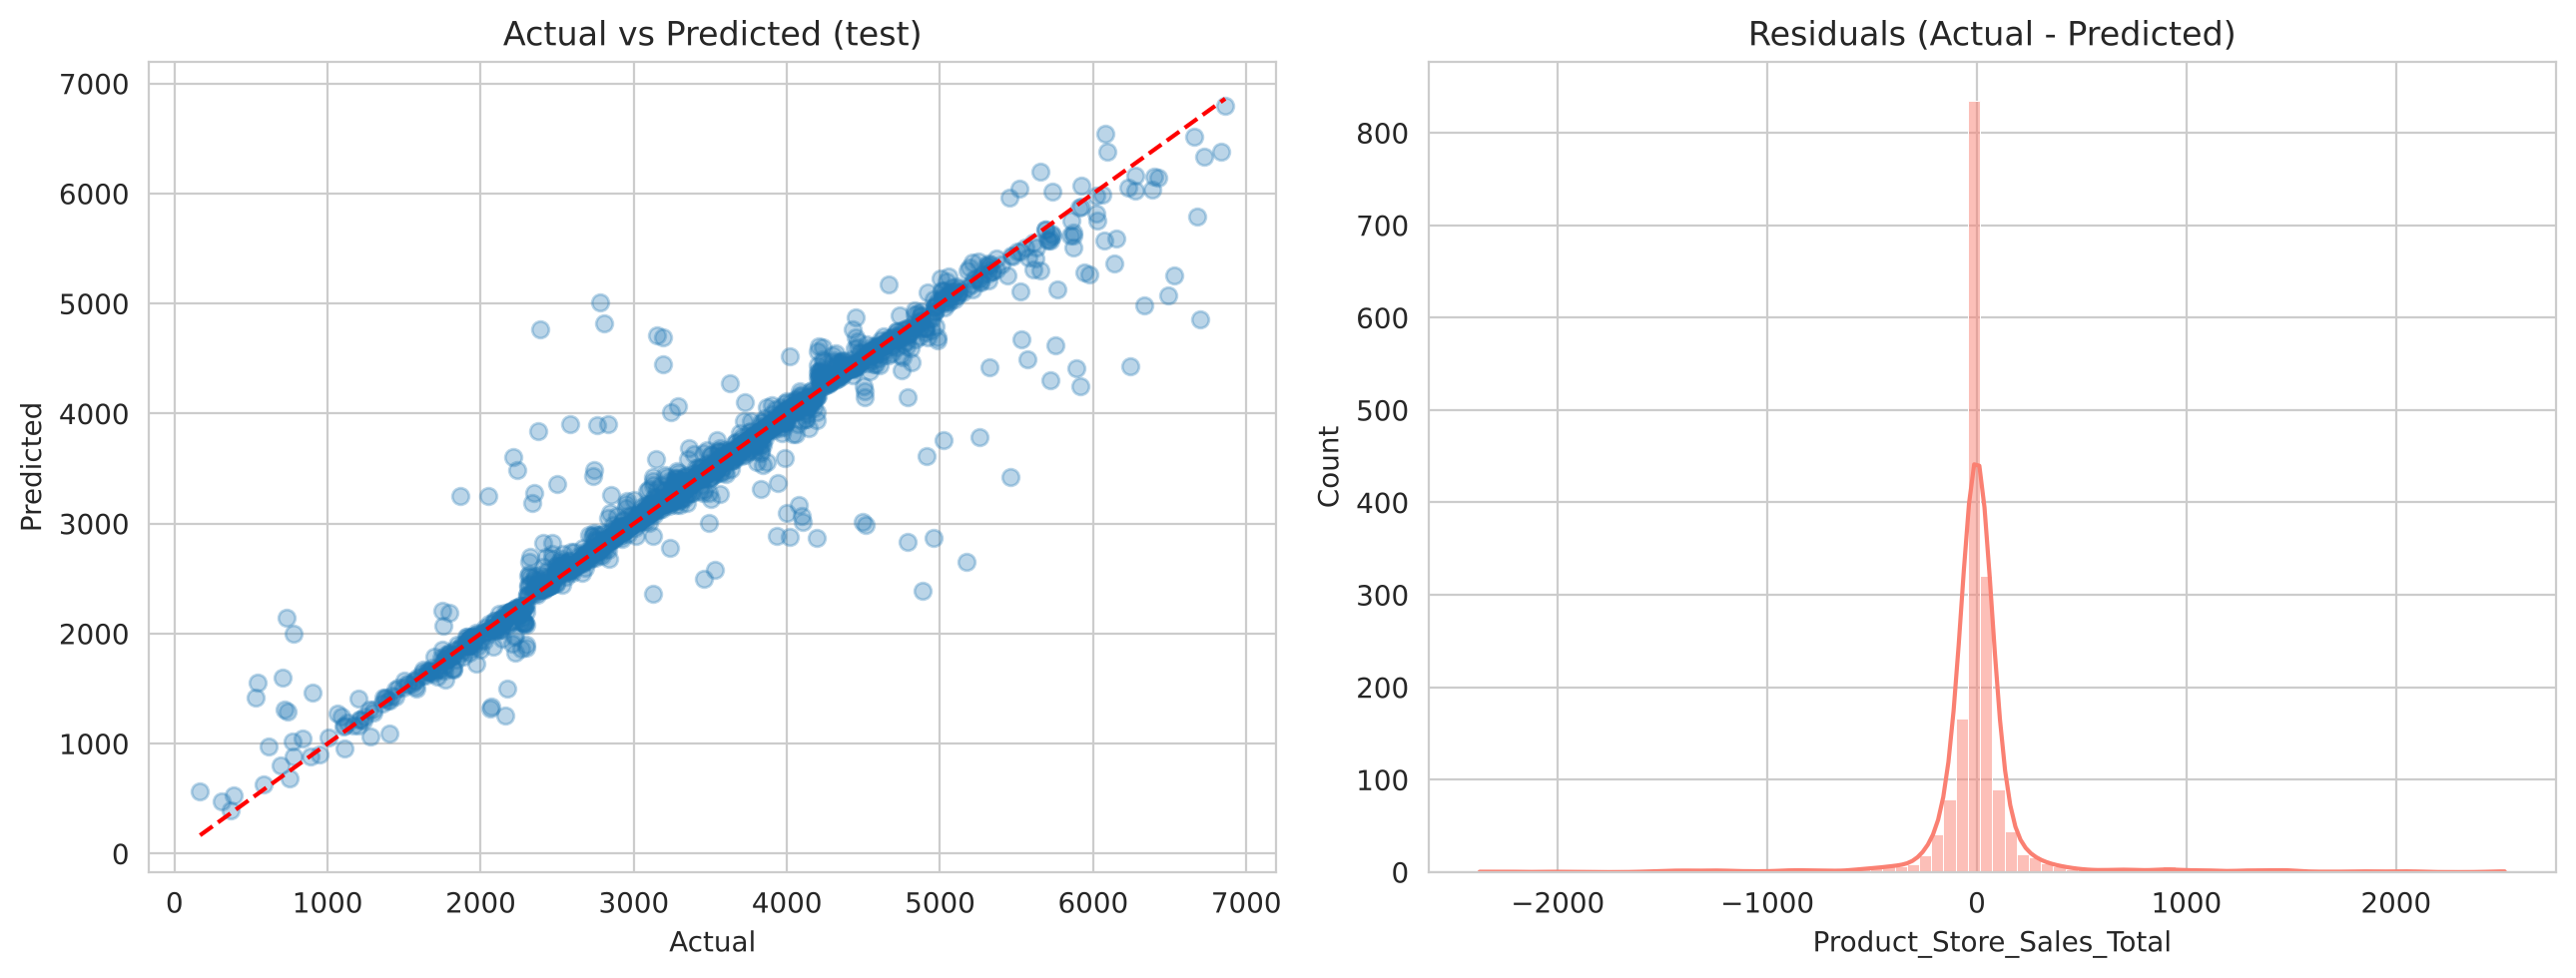

RMSE 280.7 | MAE 106.8 | R2 0.9310
Mean residual 7.25 | residual std 280.7 | residual skew 1.21


In [38]:
import joblib
model = joblib.load('models/best_model.joblib')
pred = model.predict(Xte); res_ = yte - pred
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(yte, pred, alpha=0.3); lim = [yte.min(), yte.max()]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted'); ax[0].set_title('Actual vs Predicted (test)')
sns.histplot(res_, kde=True, ax=ax[1], color='salmon'); ax[1].set_title('Residuals (Actual - Predicted)')
plt.tight_layout(); plt.show()
print('RMSE %.1f | MAE %.1f | R2 %.4f' % (np.sqrt(mean_squared_error(yte, pred)), mean_absolute_error(yte, pred), r2_score(yte, pred)))
print('Mean residual %.2f | residual std %.1f | residual skew %.2f' % (res_.mean(), res_.std(), res_.skew()))

**Observations:**
- Points hug the red 45-degree line across the whole range (about 30 to 8,000), so the model is accurate for low and high sales alike.
- Mean residual is about **+7** (near zero, versus an RMSE of 281), so there is **no material systematic bias**. The residual standard deviation (280.7) equals the RMSE, as expected for an unbiased model.
- Residual **skew is about +1.2**: the right tail is heavier than the left, meaning the occasional large error is an **under-prediction** (actual higher than predicted), typical for unusually strong sales that trees average away.
- The scatter fans out slightly at high sales, the heteroscedasticity anticipated in the EDA.

In [39]:
err = pd.DataFrame({'store_type': Xte['Store_Type'].values, 'abs_err': res_.abs().values, 'actual': yte.values, 'pct_err': (res_.abs() / yte).values * 100})
print('MAPE: %.2f%%' % err['pct_err'].mean())
print('Share of predictions within +/-10%% of actual: %.1f%%' % ((err['pct_err'] < 10).mean() * 100))
print('Predictions with abs error > 500: %d of %d (%.1f%%)' % ((err['abs_err'] > 500).sum(), len(err), (err['abs_err'] > 500).mean() * 100))
top = err['actual'] >= err['actual'].quantile(.95)
print('MAE on top-5%% sales rows: %.1f | MAE on all other rows: %.1f' % (err.loc[top, 'abs_err'].mean(), err.loc[~top, 'abs_err'].mean()))
print(); print(err.groupby('store_type')['abs_err'].mean().round(1).sort_values())

MAPE: 3.86%
Share of predictions within +/-10% of actual: 93.5%
Predictions with abs error > 500: 81 of 1753 (4.6%)
MAE on top-5% sales rows: 399.6 | MAE on all other rows: 91.3

store_type
Supermarket Type2      77.7
Food Mart             104.5
Supermarket Type1     140.6
Departmental Store    165.7
Name: abs_err, dtype: float64


**Observations:**
- **MAPE is about 3.9%** and **93.5% of predictions fall within +/-10% of the actual value**, a business-friendly accuracy statement ("nine in ten forecasts are within 10%").
- Only **81 of 1,753** test predictions (4.6%) miss by more than 500 revenue units.
- **Errors concentrate in the highest-selling rows:** MAE is about **400** for the top 5% of sales versus about **91** for the rest (4.4 times larger). Forecast risk is therefore greatest for the products that matter most financially, so procurement should hold a safety buffer on top sellers.
- **By store type**, MAE is lowest for Supermarket Type 2 (about 78) and highest for the Departmental Store (about 166). This mirrors data volume: OUT004 has 53% of the training rows (more evidence to learn from) while OUT003 has 15% and a higher-variance, higher-priced assortment.

### 6.3 Feature importance

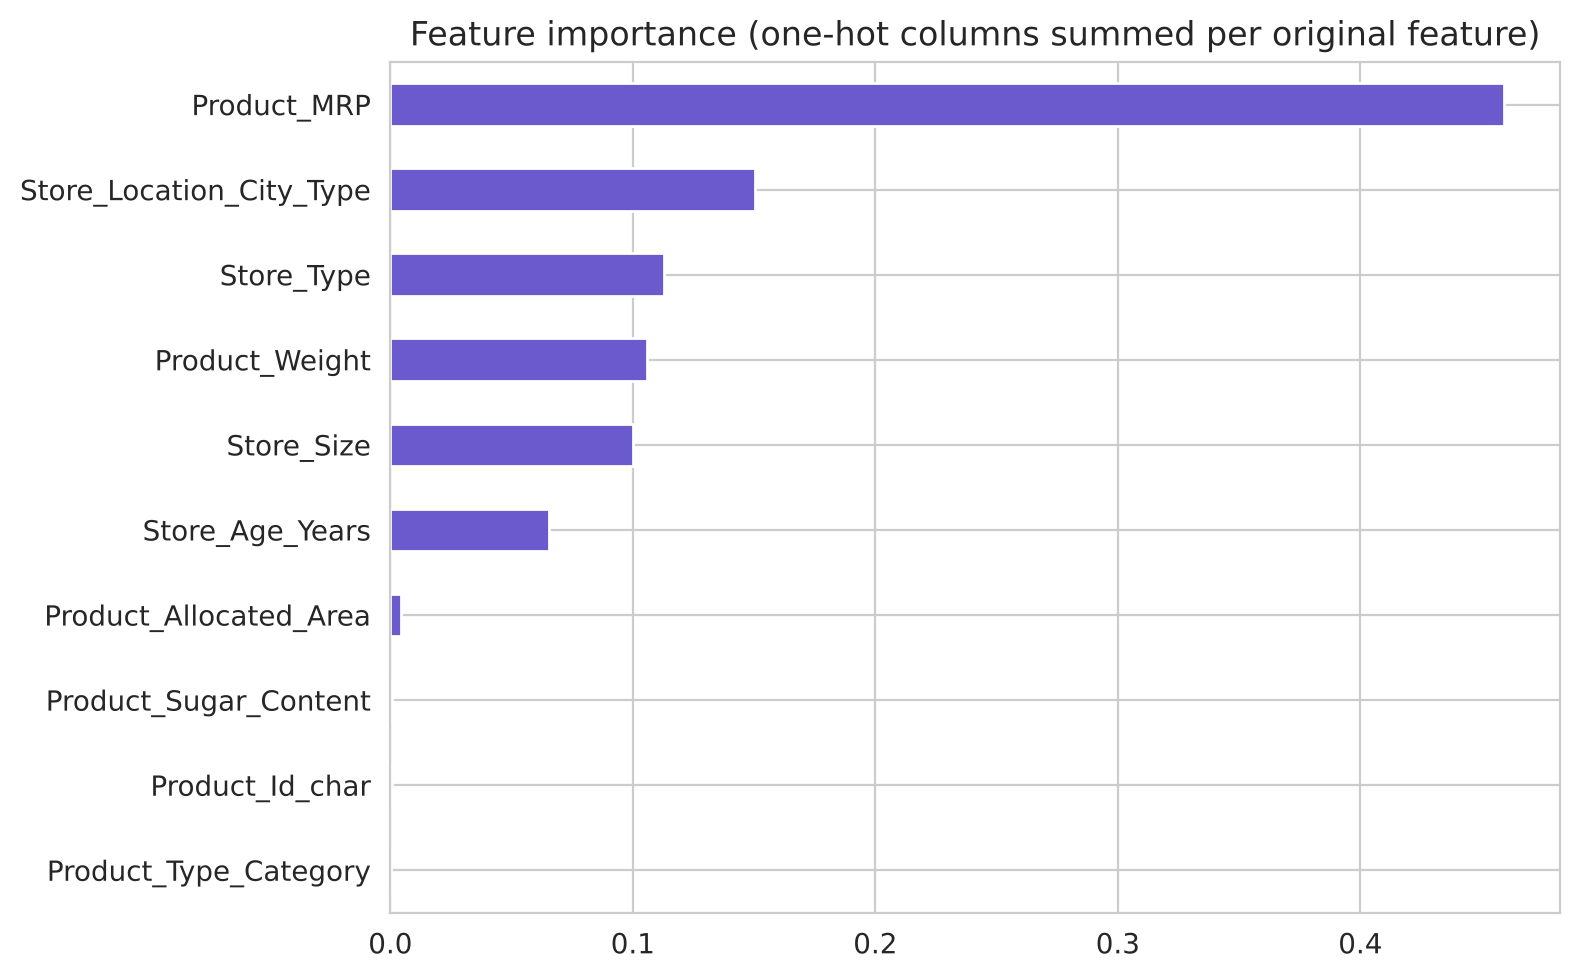

Product_MRP                 0.459
Store_Location_City_Type    0.150
Store_Type                  0.113
Product_Weight              0.106
Store_Size                  0.100
Store_Age_Years             0.066
Product_Allocated_Area      0.004
Product_Sugar_Content       0.001
Product_Id_char             0.000
Product_Type_Category       0.000
dtype: float64

All store attributes combined: 0.429


In [40]:
names = model.named_steps['prep'].get_feature_names_out()
imp = pd.Series(model.named_steps['model'].feature_importances_, index=[n.split('__')[1] for n in names])
def group(n):
    for p in ['Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Sugar_Content', 'Product_Id_char', 'Product_Type_Category']:
        if n.startswith(p): return p
    return n
grouped = imp.groupby(group).sum().sort_values(ascending=False)
grouped.iloc[::-1].plot(kind='barh', figsize=(8, 5), color='slateblue'); plt.title('Feature importance (one-hot columns summed per original feature)'); plt.tight_layout(); plt.show()
print(grouped.round(3)); print('\nAll store attributes combined:', round(grouped[['Store_Location_City_Type', 'Store_Type', 'Store_Size', 'Store_Age_Years']].sum(), 3))

**Observations:**
- Importance of one-hot columns is **summed back to the original feature**, otherwise a categorical variable looks artificially weak because its importance is split across dummies.
- **Product_MRP = 45.9%** is the dominant feature, consistent with the EDA (strongest correlation, banded scatter).
- **Store attributes together = about 43%** (city tier 15.0%, store type 11.3%, store size 10.0%, store age 6.6%). Because these four columns are different labels for the same four stores, the model is effectively splitting the importance of "which store" across them. The *combined* figure is the meaningful one.
- **Product_Weight = 10.6%** is the third driver.
- **Allocated area (0.4%), sugar content (0.1%), product-ID prefix and perishable flag (about 0%)** are essentially unused, in line with the Kruskal-Wallis tests and the zero correlation of display area.
- Impurity-based importances can be biased toward high-cardinality or continuous features; they are used here as a descriptive summary that agrees with the independent statistical tests, not as proof of causation.

### 6.4 Sanity check: reload the saved model and predict

In [41]:
sample = pd.DataFrame([{'Product_Weight': 12.5, 'Product_Sugar_Content': 'Low Sugar', 'Product_Allocated_Area': 0.07,
                        'Product_MRP': 147.0, 'Store_Size': 'Medium', 'Store_Location_City_Type': 'Tier 2',
                        'Store_Type': 'Supermarket Type2', 'Product_Id_char': 'FD',
                        'Product_Type_Category': 'Perishables', 'Store_Age_Years': 14}])
print('Predicted sales:', round(model.predict(sample)[0], 2))
print('Model file size: %.1f MB' % (os.path.getsize('models/best_model.joblib') / 1e6))
print('Reloaded model reproduces test RMSE:', round(float(np.sqrt(mean_squared_error(yte, joblib.load('models/best_model.joblib').predict(Xte)))), 1))

Predicted sales: 3378.12
Model file size: 7.8 MB


Reloaded model reproduces test RMSE: 280.7


**Observations:**
- The serialised pipeline accepts **raw feature values** and returns a prediction inside the realistic sales range, demonstrating that encoding is embedded in the model (no separate encoder needed in the app).
- The model file is about **8 MB** after compression, well below GitHub's 100 MB file limit, so it can be committed by the pipeline without Git LFS.
- Reloading the file reproduces the test RMSE of 280.7, confirming the **serialisation round-trip is lossless**, which is the key check before deployment.
- **Summary of Section 6:** the tuned Random Forest (test RMSE about 281, R2 about 0.93, MAPE about 3.9%) is the final model; it beats a mean baseline by about 74% and is unbiased, with errors concentrated on high-revenue rows.

## 7. Model Deployment (Streamlit)
`app.py` (written in Section 0) is a **Streamlit** application deployed on **Streamlit Community Cloud**. It (1) loads the model committed to the repository, (2) collects user inputs and saves them into a `DataFrame`, and (3) returns the predicted sales. `requirements.txt` is the dependency file Streamlit Cloud installs.

In [42]:
!cat app.py

"""Streamlit app for SuperKart sales forecasting."""
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="SuperKart Sales Forecast", page_icon="🛒")


@st.cache_resource
def load_model():
    return joblib.load("models/best_model.joblib")


model = load_model()

st.title("🛒 SuperKart Sales Forecast")
st.write("Predict total sales of a product in a store.")

PERISHABLE = {"Dairy", "Meat", "Fruits and Vegetables", "Breakfast", "Breads", "Seafood", "Frozen Foods"}
REFERENCE_YEAR = 2023

col1, col2 = st.columns(2)
with col1:
    st.subheader("Product")
    weight = st.number_input("Product weight", 4.0, 22.0, 12.5, step=0.1)
    sugar = st.selectbox("Sugar content", ["Low Sugar", "Regular", "No Sugar"])
    area = st.number_input("Allocated display area ratio", 0.004, 0.30, 0.07, step=0.001, format="%.3f")
    ptype = st.selectbox("Product type", [
        "Baking Goods", "Breads", "Breakfast", "Canned", "Dairy", "Frozen Foods",
        "Fruits and Vegeta

**Observations:**
- The code path is: widgets -> one-row `DataFrame` with the training column names -> `model.predict(input_df)` -> formatted result. Keeping the schema identical to training prevents **training/serving skew**.
- Feature engineering is replicated in the app (`Product_Type_Category` from the chosen product type, `Store_Age_Years = 2023 - year`), mirroring `data_prep.py`. A cleaner production design would import one shared function; here duplication is accepted for simplicity and is documented.
- The app reads `models/best_model.joblib` from the repository, so every time the workflow commits a new model, a Streamlit Cloud redeploy serves the updated forecast automatically (continuous delivery).

In [43]:
!cat requirements.txt

pandas
numpy
scikit-learn==1.9.1
joblib
streamlit
mlflow


**Observations:**
- Streamlit Community Cloud reads this file at the repository root and installs the packages before starting `app.py`.
- Pinning `scikit-learn` protects against version-mismatch errors when unpickling the model on the cloud server.
- **Deployment steps:** share.streamlit.io -> *Create app* -> choose the GitHub repository, branch `main`, main file `app.py` -> *Deploy*.

## 8. Automated GitHub Actions Workflow
`.github/workflows/pipeline.yml` automates the pipeline end to end. It triggers on **every push to `main`** and can also be started manually (`workflow_dispatch`). It consists of three chained jobs:

| Job | Action |
|---|---|
| `register-data` | Install dependencies and run the dataset validation script |
| `data-prep` | Clean, engineer features, split, and **upload train/test as a workflow artifact** |
| `model-training` | **Download the artifact**, tune and track both models with MLflow, then **commit the best model to `main`** |

In [44]:
!cat .github/workflows/pipeline.yml

name: SuperKart MLOps Pipeline

on:
  push:
    branches: [main]
    paths-ignore:
      - "models/**"
  workflow_dispatch:

permissions:
  contents: write

jobs:
  register-data:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - run: pip install -r requirements.txt
      - name: Validate and register dataset
        run: python scripts/register_data.py

  data-prep:
    needs: register-data
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - run: pip install -r requirements.txt
      - name: Clean data and create train/test split
        run: python scripts/data_prep.py
      - name: Upload train/test splits as workflow artifact
        uses: actions/upload-artifact@v4
        with:
          name: train-test-data
          path: artifacts/

  model-training:
 

**Observations:**
- **Job ordering:** `needs:` creates the dependency chain `register-data -> data-prep -> model-training`. If validation fails, no preparation or training compute is spent (fail-fast CI).
- **Artifact hand-off:** `actions/upload-artifact` and `actions/download-artifact` pass `train.csv`/`test.csv` between jobs, because each job runs on a fresh virtual machine with no shared disk. This also guarantees that training uses exactly the split that was prepared.
- **Automatic code/model update on `main`:** the last step configures a bot identity, stages `models/`, commits only if something changed (`git diff --staged --quiet ||`) and pushes to `main`. `permissions: contents: write` is required for this push.
- **Loop prevention:** `paths-ignore: models/**` plus the `[skip ci]` tag in the commit message stop the bot's own commit from re-triggering the workflow, avoiding an infinite loop.
- **Reproducibility:** Python 3.11 and the pinned `requirements.txt` give every run the same environment.

## 9. Evidence: Repository, Workflow and Deployed App
- **GitHub repository link:** `<PASTE LINK>`
- **Streamlit Community Cloud app link:** `<PASTE LINK>`

**Screenshot 1: GitHub repository folder structure** (`data/`, `scripts/`, `models/`, `app.py`, `requirements.txt`, `.github/workflows/pipeline.yml`)  
*(paste screenshot here)*

**Screenshot 2: Executed GitHub Actions workflow** (all three jobs green)  
*(paste screenshot here)*

**Screenshot 3: Streamlit app showing a prediction**  
*(paste screenshot here)*

## 10. Insights, Recommendations and Conclusion

### Key insights
1. **Price is the single strongest driver of revenue.** `Product_MRP` has the highest correlation with sales (Pearson 0.79) and the highest model importance (45.9%). Premium products contribute disproportionately.
2. **The store is the second major driver (about 43% of importance combined).** Average revenue per product ranges from about **4,947** (Departmental Store, Tier 1) to about **1,763** (Food Mart, Tier 3), a factor of 2.8. Part of this is assortment (higher MRP and heavier products in better stores) and part is volume (implied units 27.8 vs 17.0).
3. **Price effects are store-dependent.** Within-store correlation of MRP with sales ranges from 0.82 (OUT001) to 0.15 (OUT002), so price strategy cannot be copied across formats.
4. **Product weight is the third driver** (10.6% importance, correlation 0.74), partly because it moves with price (correlation 0.53 between the two).
5. **Display area, sugar content and product type do not move revenue** in this data: zero correlation for display area, and non-significant Kruskal-Wallis tests for sugar (p = 0.068) and product type (p = 0.126). Non-consumable items are always labelled "No Sugar", so the sugar column adds no independent information.
6. **The model is accurate and unbiased.** Tuned Random Forest: test RMSE about **281**, MAE about 107, R2 about **0.93**, MAPE about 3.9%, with 93.5% of predictions within 10% of actual; it cuts the error of a mean-only baseline by about 74%.
7. **Forecast error is concentrated in the highest-revenue rows** (MAE about 400 for the top 5% of sales versus about 91 elsewhere) and in the Departmental Store.

### Business recommendations
- **Procurement and supply chain:** use the model's store- and product-level forecasts for ordering, but hold a larger safety buffer for high-MRP, heavy and top-selling items where error is about four times larger; perishables should use conservative order quantities to limit spoilage.
- **Regional and format strategy:** Food Mart / Tier 3 locations lag on both price level and units sold. Test a higher-value assortment and footfall initiatives there before judging the format. Departmental Stores deliver 22% of revenue from 15% of listings, so they merit priority in range expansion.
- **Merchandising:** display area showed no relationship with revenue; reallocate space using controlled experiments (A/B tests across stores) rather than assuming more space sells more.
- **Pricing:** because price sensitivity differs by store, set and review price points per format rather than chain-wide.
- **Operations (MLOps):** retraining and redeployment occur automatically on every push; schedule the workflow (cron) once new sales data is added, monitor test RMSE across MLflow runs, and alert if it drifts above the current 281.

### Limitations
- The data has **no date column**, so it is a cross-sectional snapshot. Weekly, monthly, quarterly and annual forecasts require dated transactions to capture seasonality and trend; the present model forecasts product-store revenue.
- Only **four stores** are present and the store attributes are collinear, so store-level effects cannot be disentangled (for example Tier 3 versus Food Mart) and the model may extrapolate poorly to a new store format.
- Importance scores are descriptive, not causal. A single 80/20 split was used for the final comparison; repeated cross-validation would tighten the Random Forest versus Gradient Boosting comparison.

### Conclusion
A complete CI/CD MLOps pipeline was delivered: the SuperKart dataset is registered and validated, cleaned and enriched, split reproducibly, and used to tune and track two tree-based models in MLflow. The best model (Random Forest, R2 about 0.93, RMSE about 281) is committed to the repository by a GitHub Actions workflow and served through a Streamlit web application, so the business can obtain consistent, up-to-date forecasts with minimal manual effort. The analysis also shows *where* sales come from (price, weight and store format) and *where* the forecast is least reliable (the highest-revenue products), providing actionable guidance for procurement, regional planning and merchandising.